# Module 8 - Final Project 


**In this final project, you will demonstrate what you have learned in this class by applying a thorough data analysis to a data set of your choice.** 

As discussed on the discussion boards in the last two weeks, your data set should contain rich enough features and a good sample size so that you can apply the methods you have learned to derive some **insights** from the data. The ultimate goal of data analysis is to learn from the data so that we can form useful and actionable knowledge. 

**Predictive models are only useful if you can interpret the data, find out influential variables, derive insights that are useful and actionable for your audience!**

---

Use this notebook for the analysis of your final project. **Your deliverables for the final project are:** 

- **This notebook**: contains the **full** data science project life cycle as you have learned in the Intro class. 
 
   - Load your data, clean your data, include all the carpentry you need to put it into some shape for your later analysis. 
            
  - EDA: exploratory data analysis: this is where you do the univariate and multivariate analyses; visualize your data to understand the shape and associations in it. Plot densities, histograms, scatter plots, etc. Look for correlations, patterns, clusters, etc.     
   
  - Modeling and hypothesis testing: use any of the adequate techniques to see if you can model the influence of the variables on each other. You can try to reduce dimensionality, try to do regression analysis, hypothesis testing, etc. to see how variables affect each other.    
   
  - **Insights:** the point of data analysis to derive **insights** from your data. What do you see? What did you learn from the data? Did it answer your initial question or did it verify your hypothesis? 
   
   
- **A PDF file** that contains a **few** slides to summarize your results: similar to the data vis course, create a pdf document that contains up to 4-5 slides (**no more**) to present your results. Make sure to put the pdf file **in the `exercises` folder of module 8**. Communicate your results effectively using visualization principles you have learned and provide useful and actionable insights for your audience. 
 
 
 
- Upload your data set to this folder (under exercises folder). 
 
 ---
 
 
 **You should have ample explanation and comments for all your data analysis in this notebook.** Think of it as a LAB notebook: imagine that you are creating a lab notebook for others to follow and learn from your analysis. You should have enough details so that somebody can recreate your analysis by following your descriptions and explanations. 
 
Have a markdown cell before each code cell explaining **what** you are doing and **why** you are doing it. Have comments in the code cell. Have a markdown cell **after** every code cell explaining what you just found out by running that code cell before. 
 
 ---
 
 

## 1. Loading, Cleaning, Displaying Data 

Explain your data set here; 

 - what is it about? 
 - This data set explores food access broken down by census tracts. I have narrowed down the data to just Missouri to make it more manageable. It comes from the Food Access Research Atlas (https://www.ers.usda.gov/data-products/food-access-research-atlas/download-the-data) compiled by the USDA.
 - What are the variables? 
 - The variables I am focusing on are percent on SNAP, percent Minority, Census Tract, County, if the area is urban, population as of 2010, median family income, low access population beyond 1/2 mile from a supermarket, and low access & low income beyond 1/2 mile from a supermarket. 
 - What do you want to do with it? (your research questions or hypotheses if you have any) 
 - I would like to look at the relationship between SNAP benefits and poverty depending on race percentages. I would also like to see if low income - low access factors effect this relationship
 - How are you going to clean it? etc. 
- I am going to create variables for pctSNAP and pctMinority, change variable types (specifically census tract which I want as character, not numeric), change Urban to say "urban" or "rural" instead of 1 or 2, then I will check for any NA's and decide what to do with them.

In [56]:
library(dplyr)
# load your data, 
food_access <- read.csv('mo food access.csv', stringsAsFactors = FALSE)
#display food access to help choose which variables to keep
#create percentages to work with by dividing amount in each tract by total amount in the tract
head(food_access)

food_access$pctSNAP<- round((food_access$TractSNAP/food_access$OHU2010) * 100, 2)
food_access$pctWhite<- round((food_access$TractWhite/food_access$Pop2010) * 100, 2)
food_access$pctBlack<- round((food_access$TractBlack/food_access$Pop2010) * 100, 2)
food_access$pctAsian<- round((food_access$TractAsian/food_access$Pop2010) * 100, 2)
food_access$pctNHOPI<- round((food_access$TractNHOPI/food_access$Pop2010) * 100, 2)
food_access$pctAIAN<- round((food_access$TractAIAN/food_access$Pop2010) * 100, 2)
food_access$pctOMultir<- round((food_access$TractOMultir/food_access$Pop2010) * 100, 2)
food_access$pctHispanic<- round((food_access$TractHispanic/food_access$Pop2010) * 100, 2)
food_access$pctMinority <- (food_access$pctBlack + food_access$pctAsian + food_access$pctNHOPI + food_access$pctAIAN + food_access$pctHispanic)

# #select variables to work with, since I want to specifically look at the relationship between pctSNAP, PovertyRate, and pctMinority
# #I selected those variables and a few extras I believe could be helpful
food_access <- food_access %>% select(CensusTract, County, Urban, Pop2010, PovertyRate, 
                                      MedianFamilyIncome, lapophalfshare, lalowihalfshare, pctMinority, pctSNAP)
food_access$CensusTract <- as.character(food_access$CensusTract)
food_access$MedianFamilyIncome <- as.numeric(food_access$MedianFamilyIncome)
food_access$lapophalfshare <- as.numeric(food_access$lapophalfshare)
food_access$lalowihalfshare <- as.numeric(food_access$lalowihalfshare)
food_access$Urban <- factor(if_else(food_access$Urban == 1 , "urban", "rural"))

# # check I selected the correct variables 
str(food_access)
head(food_access)

,CensusTract,State,County,Urban,Pop2010,OHU2010,GroupQuartersFlag,NUMGQTRS,PCTGQTRS,LILATracts_1And10,⋯,TractSeniors,TractWhite,TractBlack,TractAsian,TractNHOPI,TractAIAN,TractOMultir,TractHispanic,TractHUNV,TractSNAP
,<dbl>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,29001950100,Missouri,Adair County,0,3802,1456,0,0,0.00,0,⋯,553,3720,7,21,0,17,37,22,75,96
2,29001950200,Missouri,Adair County,0,3019,1223,0,0,0.00,0,⋯,510,2964,5,8,0,12,30,22,87,157
3,29001950300,Missouri,Adair County,1,2951,1388,0,52,1.76,0,⋯,269,2721,49,73,3,10,95,77,162,266
4,29001950400,Missouri,Adair County,0,3892,1727,0,41,1.05,0,⋯,663,3703,36,60,4,13,76,83,107,184
5,29001950500,Missouri,Adair County,1,7079,2992,0,379,5.35,1,⋯,998,6581,149,134,2,20,193,172,152,234
6,29001950900,Missouri,Adair County,1,2277,1017,0,0,0.00,0,⋯,208,2086,41,81,1,4,64,51,136,89


Warning message in eval(expr, envir, enclos):
“NAs introduced by coercion”
Warning message in eval(expr, envir, enclos):
“NAs introduced by coercion”
Warning message in eval(expr, envir, enclos):
“NAs introduced by coercion”


'data.frame':	1391 obs. of  10 variables:
 $ CensusTract       : chr  "29001950100" "29001950200" "29001950300" "29001950400" ...
 $ County            : chr  "Adair County" "Adair County" "Adair County" "Adair County" ...
 $ Urban             : Factor w/ 2 levels "rural","urban": 1 1 2 1 2 2 2 1 2 1 ...
 $ Pop2010           : int  3802 3019 2951 3892 7079 2277 2587 5439 6738 2063 ...
 $ PovertyRate       : num  13.5 15.3 39.3 18.6 27.8 50.2 63.3 5.7 9.6 11.8 ...
 $ MedianFamilyIncome: num  57226 62222 52429 60216 79622 ...
 $ lapophalfshare    : num  98.5 100 70.5 72.3 100 ...
 $ lalowihalfshare   : num  35.4 35.1 41.9 27.1 43.1 ...
 $ pctMinority       : num  1.76 1.56 7.18 5.02 6.73 ...
 $ pctSNAP           : num  6.59 12.84 19.16 10.65 7.82 ...


,CensusTract,County,Urban,Pop2010,PovertyRate,MedianFamilyIncome,lapophalfshare,lalowihalfshare,pctMinority,pctSNAP
,<chr>,<chr>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,29001950100,Adair County,rural,3802,13.5,57226,98.53,35.43,1.76,6.59
2,29001950200,Adair County,rural,3019,15.3,62222,100.00,35.12,1.56,12.84
3,29001950300,Adair County,urban,2951,39.3,52429,70.48,41.90,7.18,19.16
4,29001950400,Adair County,rural,3892,18.6,60216,72.31,27.09,5.02,10.65
5,29001950500,Adair County,urban,7079,27.8,79622,100.00,43.13,6.73,7.82
6,29001950900,Adair County,urban,2277,50.2,42133,32.77,28.54,7.82,8.75


In [57]:
#check for any NA's in food_access
sapply(food_access, function(x) sum(is.na(x)))


CensusTract             County              Urban            Pop2010 
                 0                  0                  0                  0 
       PovertyRate MedianFamilyIncome     lapophalfshare    lalowihalfshare 
                 0                  9                 11                 11 
       pctMinority            pctSNAP 
                 0                  0

In [58]:
#I used this data frame to help decide what to do with my NA values found above
food_access %>% group_by(County) %>% summarize(mean_MFI = mean(MedianFamilyIncome, na.rm = TRUE),
                                               mean_lph = mean(lapophalfshare, na.rm = TRUE),
                                              mean_lalihs = mean(lalowihalfshare, na.rm = TRUE)) %>% head()

County,mean_MFI,mean_lph,mean_lalihs
<chr>,<dbl>,<dbl>,<dbl>
Adair County,58974.67,82.01286,39.30714
Andrew County,70708.25,90.60500,26.40000
Atchison County,64402.00,80.45500,25.81000
Audrain County,54634.29,86.53857,34.91286
Barry County,51316.43,94.45571,43.84286
Barton County,54301.67,99.50000,40.77000


In [59]:
#look at which county's are missing MedianFamilyIncome
food_access %>% select(County, CensusTract ,MedianFamilyIncome)%>% filter(is.na(MedianFamilyIncome))

County,CensusTract,MedianFamilyIncome
<chr>,<chr>,<dbl>
Adair County,29001951000,NA
Boone County,29019000500,NA
Jackson County,29095980101,NA
Jackson County,29095989100,NA
Platte County,29165030307,NA
St. Charles County,29183980000,NA
St. Louis County,29189213102,NA
St. Louis city,29510106200,NA
St. Louis city,29510118400,NA


In [60]:
food_access %>% select(County,lalowihalfshare, pctSNAP, MedianFamilyIncome)%>% filter(is.na(lalowihalfshare))

County,lalowihalfshare,pctSNAP,MedianFamilyIncome
<chr>,<dbl>,<dbl>,<dbl>
Greene County,NA,13.08,42222
Jackson County,NA,50.54,31250
Jackson County,NA,51.92,19976
Jackson County,NA,1.76,70250
St. Louis County,NA,1.14,101613
St. Louis city,NA,11.66,57583
St. Louis city,NA,8.56,92500
St. Louis city,NA,39.39,33417
St. Louis city,NA,43.18,29219


In [61]:
food_access %>% select(County,lapophalfshare, MedianFamilyIncome, pctSNAP)%>% filter(is.na(lapophalfshare))

County,lapophalfshare,MedianFamilyIncome,pctSNAP
<chr>,<dbl>,<dbl>,<dbl>
Greene County,NA,42222,13.08
Jackson County,NA,31250,50.54
Jackson County,NA,19976,51.92
Jackson County,NA,70250,1.76
St. Louis County,NA,101613,1.14
St. Louis city,NA,57583,11.66
St. Louis city,NA,92500,8.56
St. Louis city,NA,33417,39.39
St. Louis city,NA,29219,43.18


after reviewing the NA values and comparing with other values for each county, including means for the missing values, I believe it is best to remove the NA values. There is such a big difference even within counties, that I do not feel replacing with a mean or median will help to provide meaningful data analysis.

In [62]:
food_access <- na.omit(food_access)
sapply(food_access, function(x) sum(is.na(x)))

CensusTract             County              Urban            Pop2010 
                 0                  0                  0                  0 
       PovertyRate MedianFamilyIncome     lapophalfshare    lalowihalfshare 
                 0                  0                  0                  0 
       pctMinority            pctSNAP 
                 0                  0

## 2. Exploratory Data Analysis 

Have your **multiple** code and markdown cells here to explore the data. 

 - descriptive statistics 
 - univariate, multivariate, 
 - histograms, correlations, associations, scatter plots
 - do correlations hold for subgroups??? (Simpson's paradox) 
 - are there any meaningful clusters? 
 - linearity checks, etc. 


run the summary function on food_access. This gives good idea of our variables and can also help us figure out important things about them like if they are discrete or continuous.

In [63]:
summary(food_access)

 CensusTract           County            Urban        Pop2010     
 Length:1371        Length:1371        rural:457   Min.   :  102  
 Class :character   Class :character   urban:914   1st Qu.: 2992  
 Mode  :character   Mode  :character               Median : 4113  
                                                   Mean   : 4341  
                                                   3rd Qu.: 5488  
                                                   Max.   :12720  
  PovertyRate    MedianFamilyIncome lapophalfshare   lalowihalfshare
 Min.   : 0.00   Min.   : 15602     Min.   :  0.00   Min.   : 0.00  
 1st Qu.: 7.60   1st Qu.: 48728     1st Qu.: 63.53   1st Qu.:13.97  
 Median :13.50   Median : 61576     Median : 85.61   Median :25.08  
 Mean   :15.58   Mean   : 68002     Mean   : 77.45   Mean   :26.22  
 3rd Qu.:21.00   3rd Qu.: 80408     3rd Qu.: 99.89   3rd Qu.:36.58  
 Max.   :75.90   Max.   :238155     Max.   :100.00   Max.   :78.68  
  pctMinority        pctSNAP      
 Min.   : 0.5

Reading our summary results we can see a few different things. First, we can ignore CensusTract and County since these are used solely for identification purposes. From our Urban variable we can see that around 67% of our data is in an Urban area (931/1391). Pop2010 is discrete and shows us that the minimum population is 1, the maximum population is 12,720, and the average population per census tract is 4,305. Poverty Rate is discrete and I find it interesting that the mean poverty rate is actually quite low at 15.73. I would expect that with more urban areas than rural areas, we would see a higher mean poverty rate. Median Family Income is continuous and has a very large range (15,602 - 238,155). Lapophalfshare and lalowihalfshare are measuring similar things, but we see that while there is at least one tract with 100% of the population at least 1/2 mile from a supermarket, the same can not be said for low-access & low-income which has a max of 79.33. The percentage of minorities in a tract is discrete (since it is measuring people) and ranges from 0 - 100%. Lastly, the percentage of housing units in each tract receiving SNAP is also discrete and ranges from 0 - 53.47%. Let's see what else we can learn!

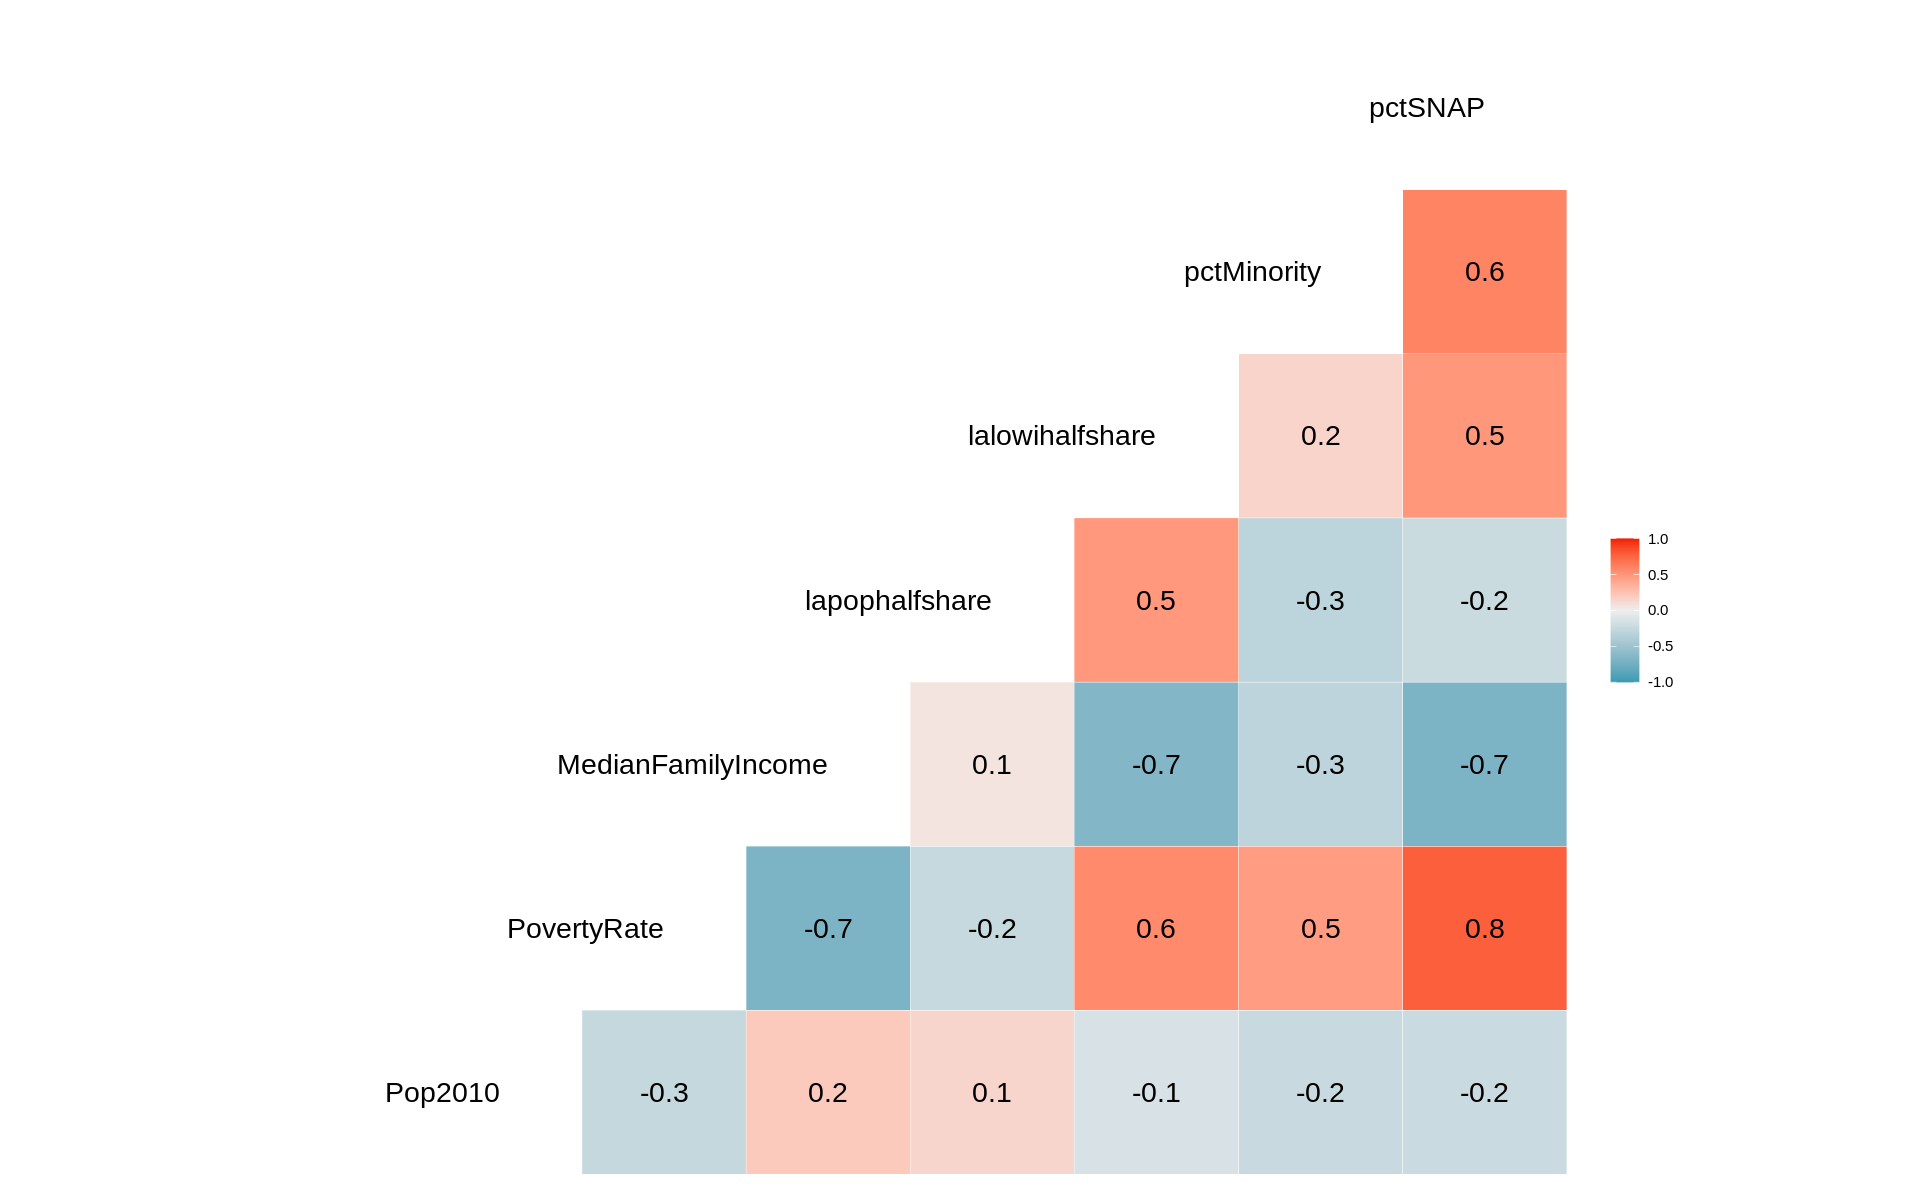

In [64]:
# load GGally library
library(GGally)
#create a correlation matrix to view relationships between the variables
#I am most interested in the relationships between pctSNAP, pctMinority, and PovertyRate
ggcorr(food_access[,4:10], label = TRUE ,label_size=6, hjust=1, size = 6, layout.exp = 1)

We see that the biggest positive correlations are between pctSNAP and PovertyRate (0.8), pctSNAP and pctMinority (0.6), and lalowihalfshare and PovertyRate (0.6). I see larger negative correlations betweeen PovertyRate and MedianFamilyIncome, lalowihalfshare and MedianFamilyIncome, and pctSNAP and MedianFamilyIncome all at -0.7.

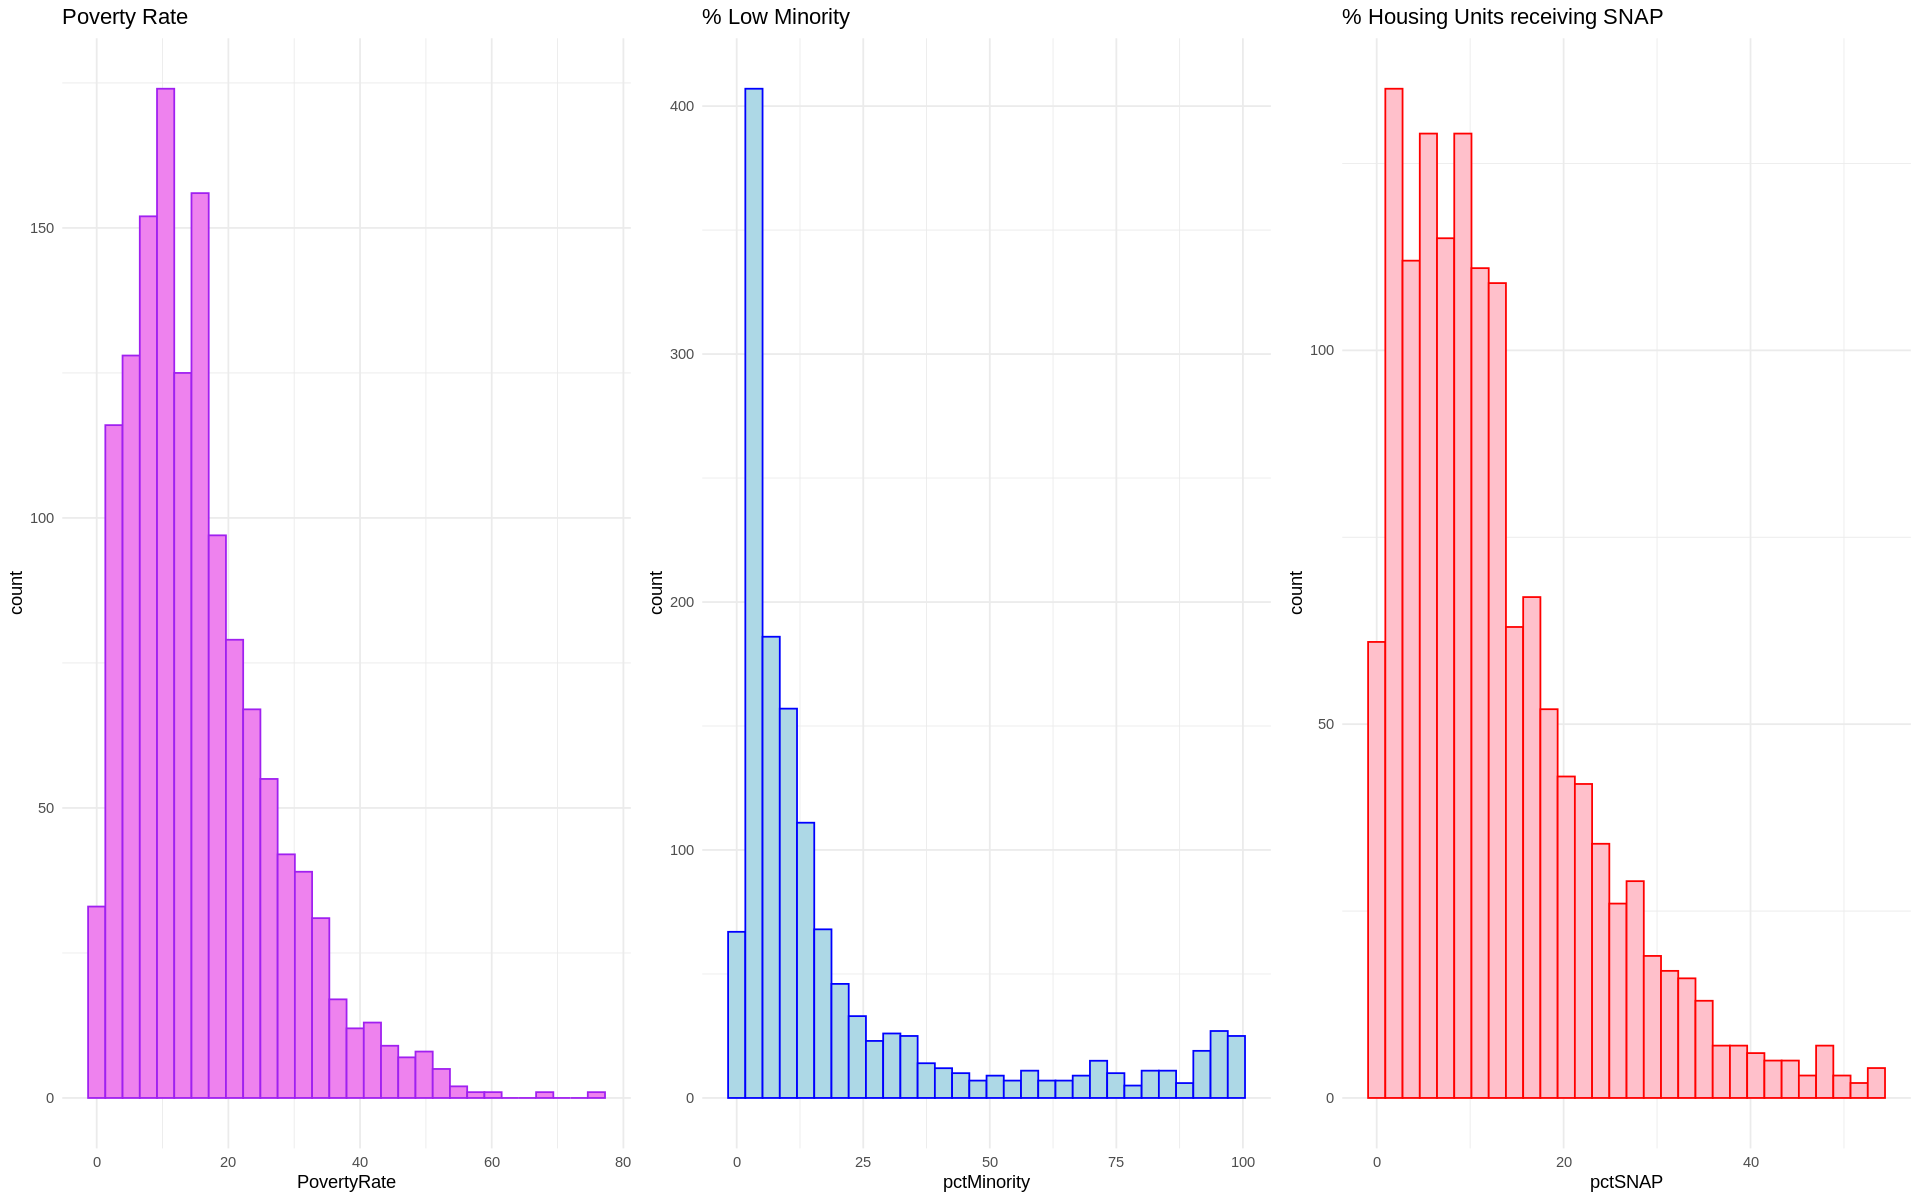

In [65]:
#plot histograms for the variables I am most interested in to see if any trends begin to stick out
library(gridExtra)
library(repr)
options(repr.plot.width=16, repr.plot.height=10)
grid.arrange(
ggplot(food_access, aes(x=PovertyRate)) + geom_histogram(bins=30, col="purple", fill="violet") + 
    labs(title = "Poverty Rate") +theme_minimal(),
ggplot(food_access, aes(x=pctMinority)) + geom_histogram(bins=30, col="blue", fill="lightblue") + 
    labs(title = "% Low Minority")+theme_minimal(),
ggplot(food_access, aes(x=pctSNAP)) + geom_histogram(bins=30, col="red", fill="pink") + 
    labs(title = "% Housing Units receiving SNAP")+theme_minimal(),
ncol=3)

All 3 of the above histograms are right skewed. This means most of our values for PovertyRate, pctMinority, and pctSNAP are on the lower end, with fewer high values in each variable. Our medians for each variable should be lower than the means because of this skew. All three histograms are unimodal, but pctSNAP appears the closest to being bimodal.

Now, let's see how these variables (PovertyRate, pctMinority, and pctSNAP) compare between urban and rural populations using box plots. We will also look at the mean for each variable between urban and rural.

Urban,Mean_Min,n
<fct>,<dbl>,<int>
rural,4.959825,457
urban,27.018917,914


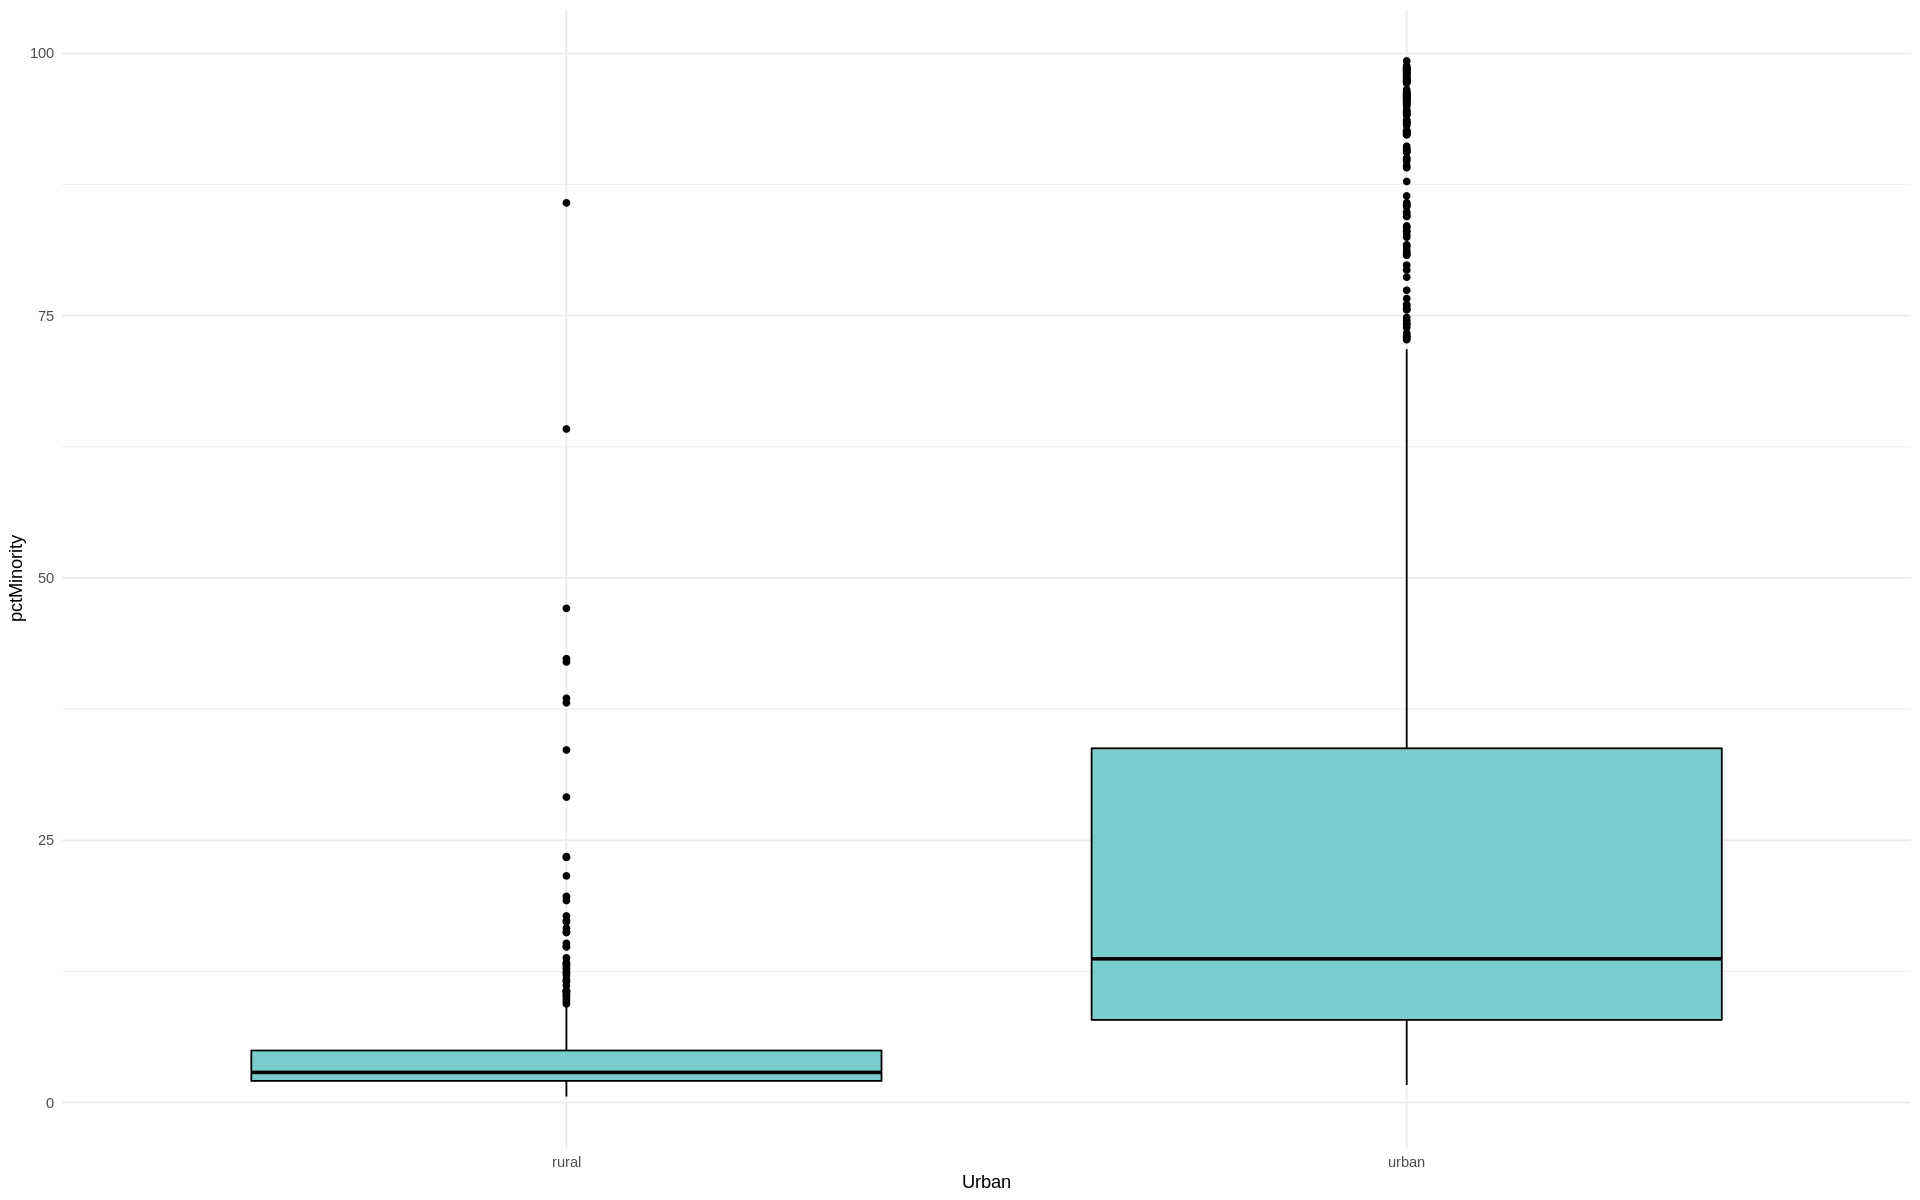

In [66]:
food_access %>% group_by(Urban) %>% summarize(Mean_Min = mean(pctMinority), n=n())
ggplot(food_access, aes(x=Urban, y=pctMinority)) + geom_boxplot(col="black", fill="darkslategray3") +theme_minimal()

The above boxplot shows the percentage of minorities in the tract population compared between urban and rural settings. The rural boxplot is very short which tells us that there are relatively low percentages of minorities in rural tracts. However we do see outliers above the plot ranging all the way to 100%. The urban side has a much more even spread, but the median is towards the lower range of the data. It also has outliers above the plot ranging to almost 100%. 

Urban,mean_poverty,n
<fct>,<dbl>,<int>
rural,14.07177,457
urban,16.33829,914


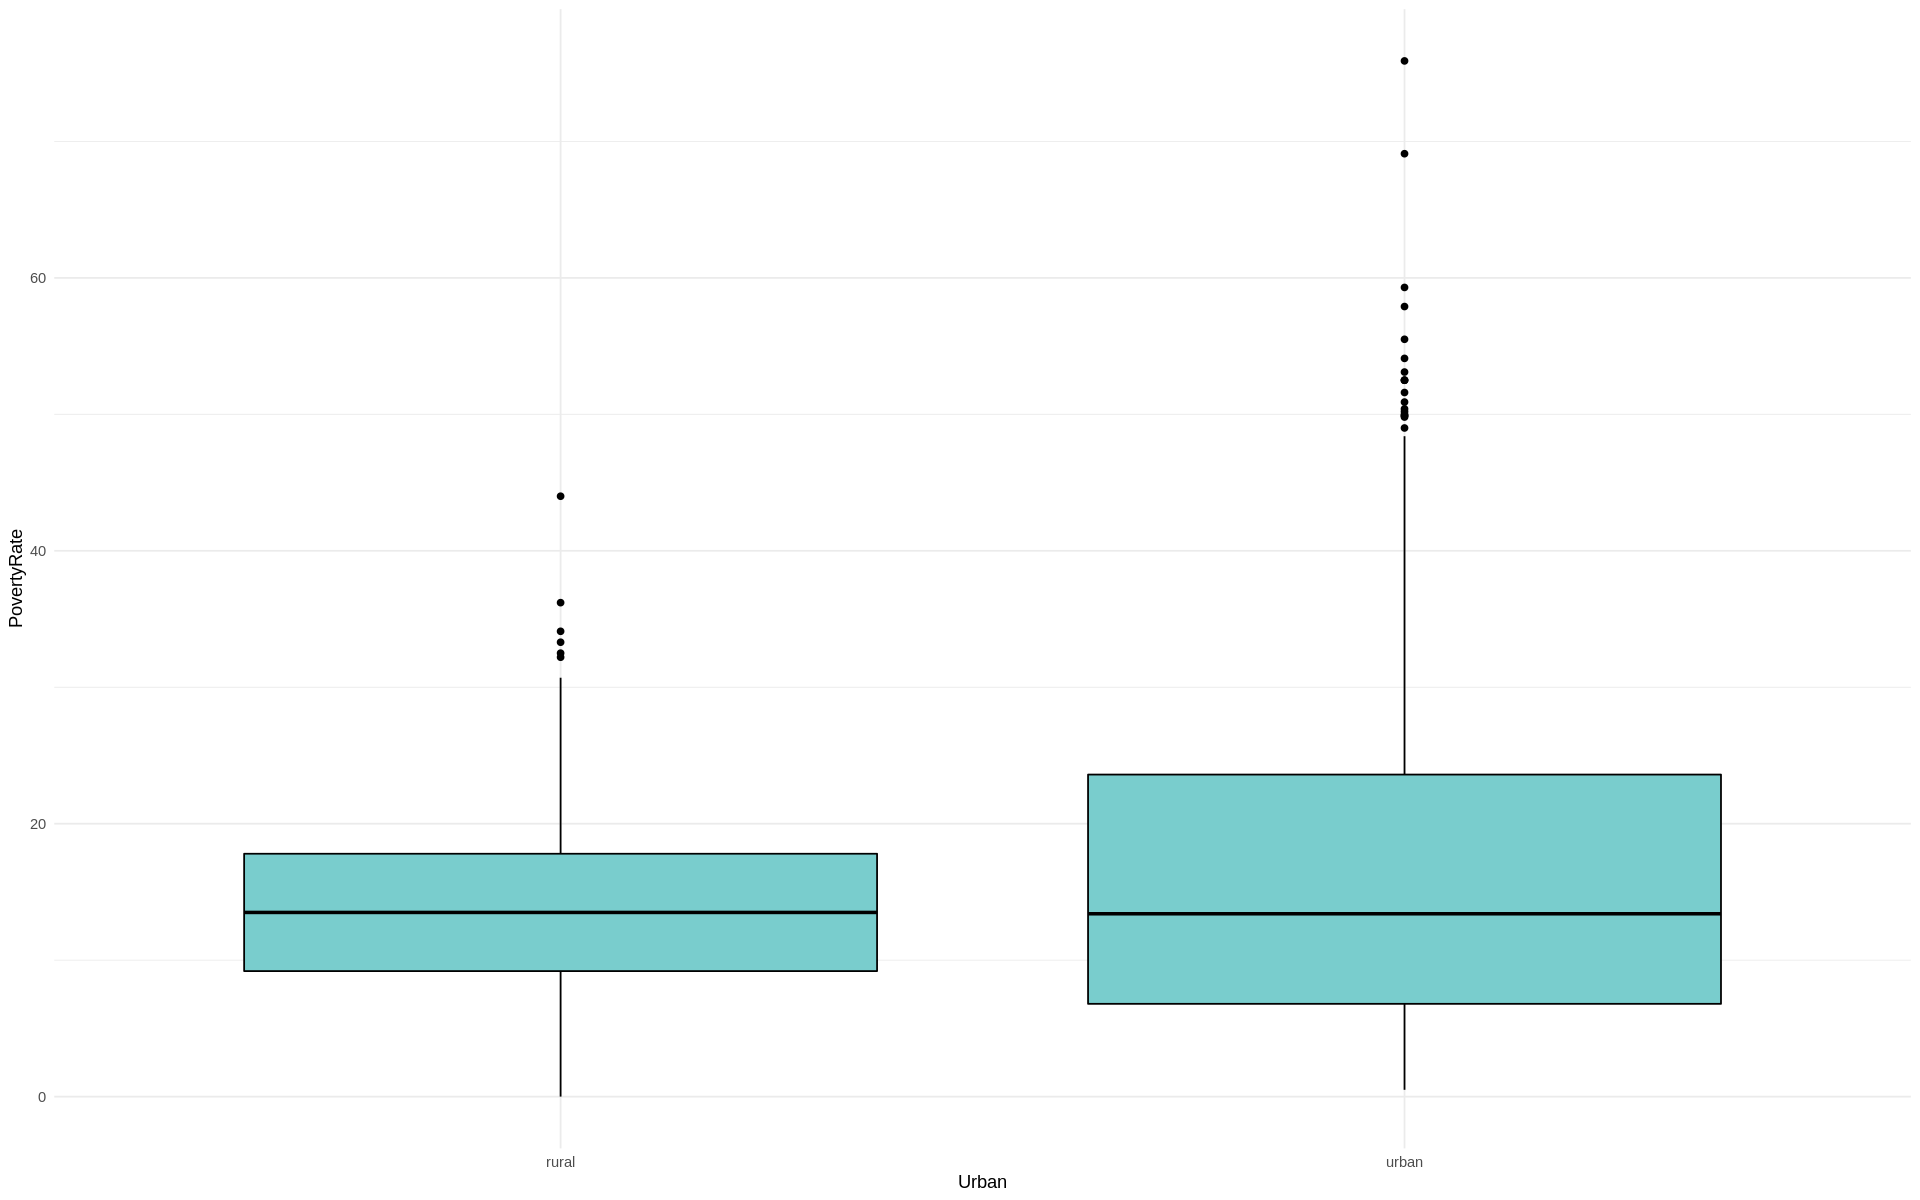

In [67]:
food_access %>% group_by(Urban) %>% summarize(mean_poverty = mean(PovertyRate, na.rm = TRUE), n=n())

ggplot(food_access, aes(x=Urban, y=PovertyRate))  + geom_boxplot(col="black", fill="darkslategray3") +theme_minimal()

The above box plot looks at the poverty rate for each tract compared between rural and urban settings. The rural box is shorter than the urban box and appears to be more evenly distributed with the median appearing to be right in the middle. The rural box also has a smaller range for its outliers with them reaching to about 45%. The urban box is larger which aligns with there being more tracts that are urban. The urban box has more outliers that range all the way up to about 75%.

Urban,mean_snap,n
<fct>,<dbl>,<int>
rural,10.86346,457
urban,13.54287,914


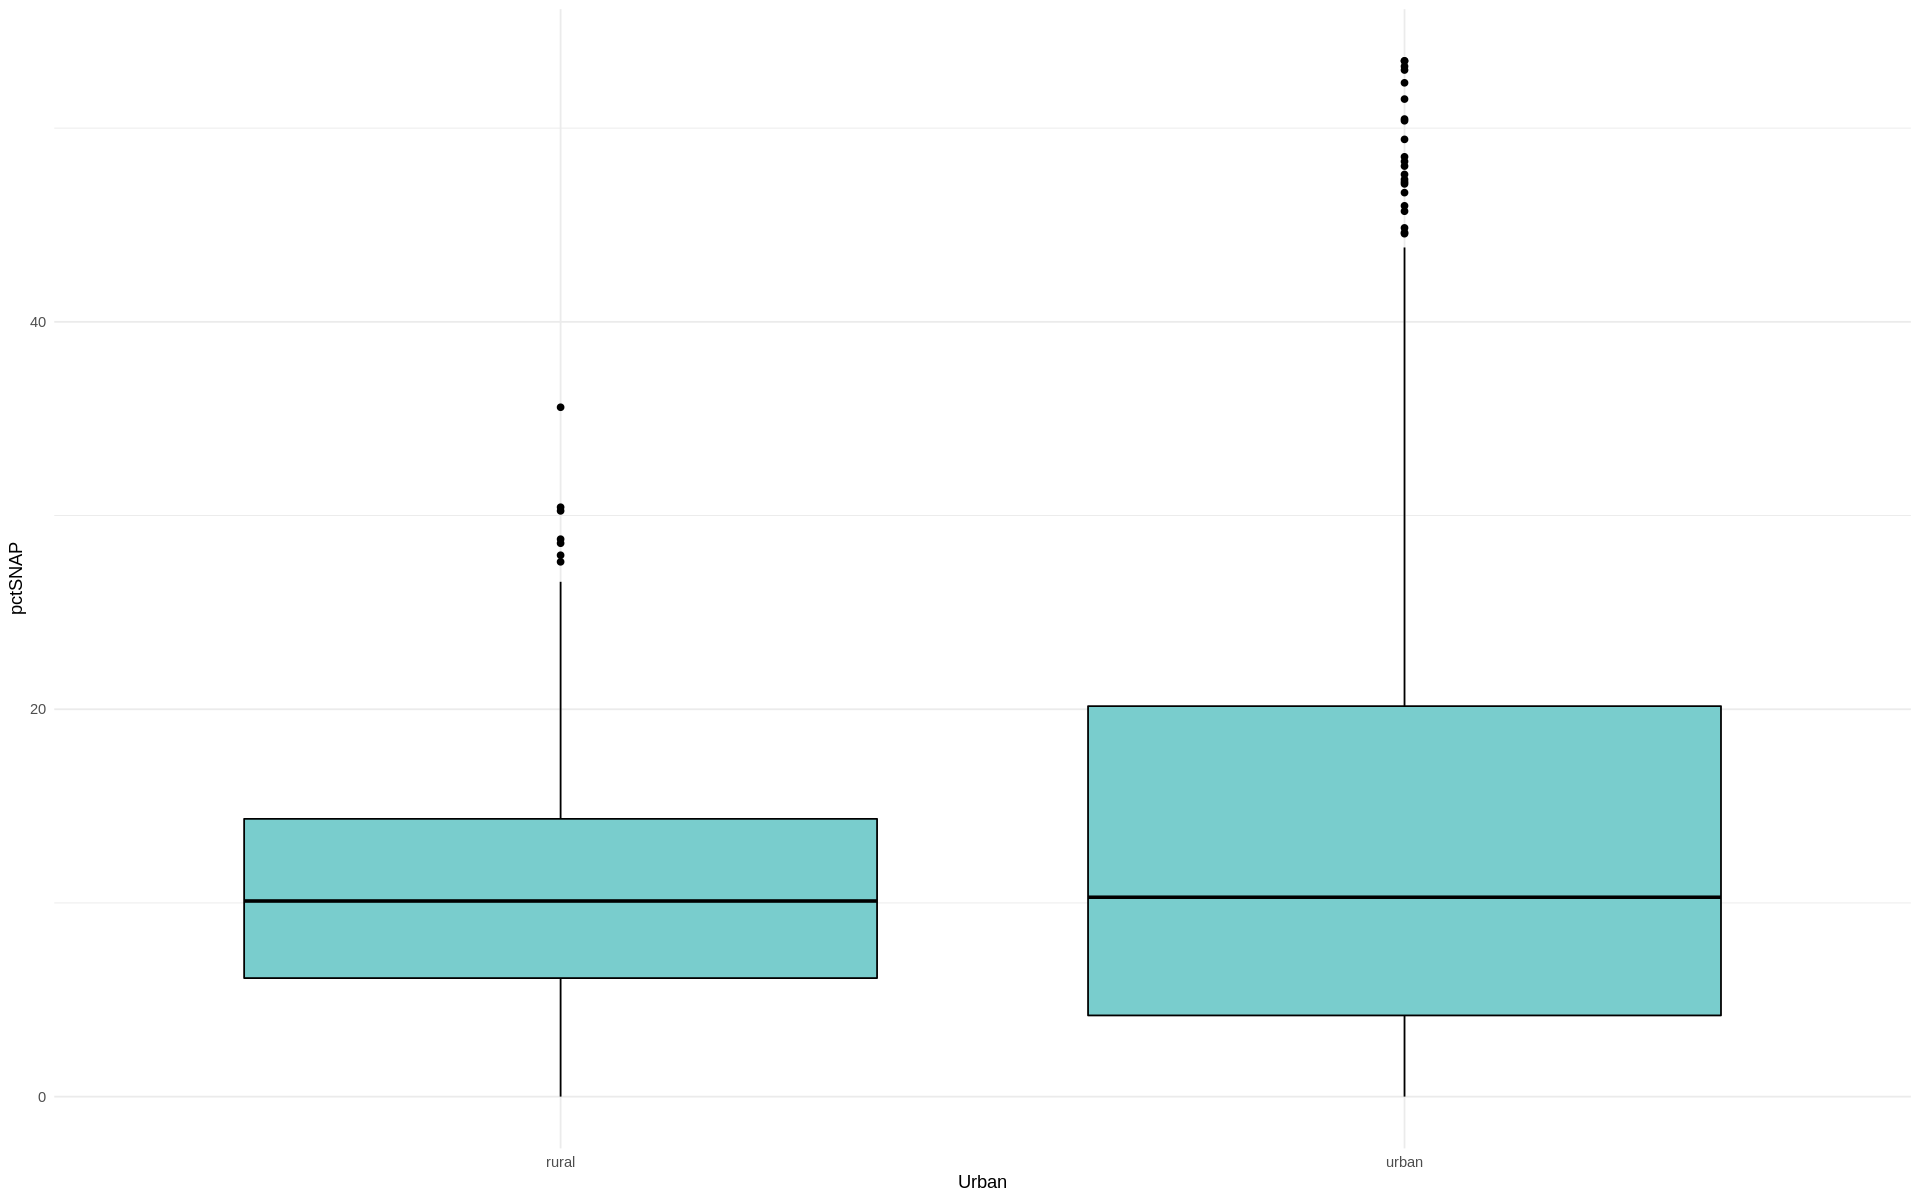

In [68]:
food_access %>% group_by(Urban) %>% summarize(mean_snap = mean(pctSNAP, na.rm = TRUE), n=n())

ggplot(food_access, aes(x=Urban, y=pctSNAP))  + geom_boxplot(col="black", fill="darkslategray3") +theme_minimal()

The above box plot looks at the percentage of housing units in each tract on SNAP benefits compared between urban and rural. In this plot, the medians for both rural and urban are almost the same, but the distributions are different. The rural box is fairly evenly distributed above and below the median. The urban plot is not evenly distributed with more values above the median. Both plots have outliers with rural ranging to about 35% and urban ranging to about 55%.

Now, let's move into looking at relationships between two variables using scatter plots. We will look at the relationships of lapophalfshare, lalowihalfshare, PovertyRate, and pctMinority to pctSNAP. These are the variables we are interested in using to predict values of pctSNAP, so it is important to understand how they are related to each other. Additionally, the points are labelled by if they are urban or rural to see if any patterns emerge.

`geom_smooth()` using formula 'y ~ x'

`geom_smooth()` using formula 'y ~ x'

`geom_smooth()` using formula 'y ~ x'

`geom_smooth()` using formula 'y ~ x'



[1] "The correlation of lapophalfshare and pctSNAP is -0.227249126968094"

[1] "The correlation of lalowihalfshare and pctSNAP is 0.496005190143013"

[1] "The correlation of PovertyRate and pctSNAP is 0.77570236897946"

[1] "The correlation of pctMinority and pctSNAP is 0.594635153854254"

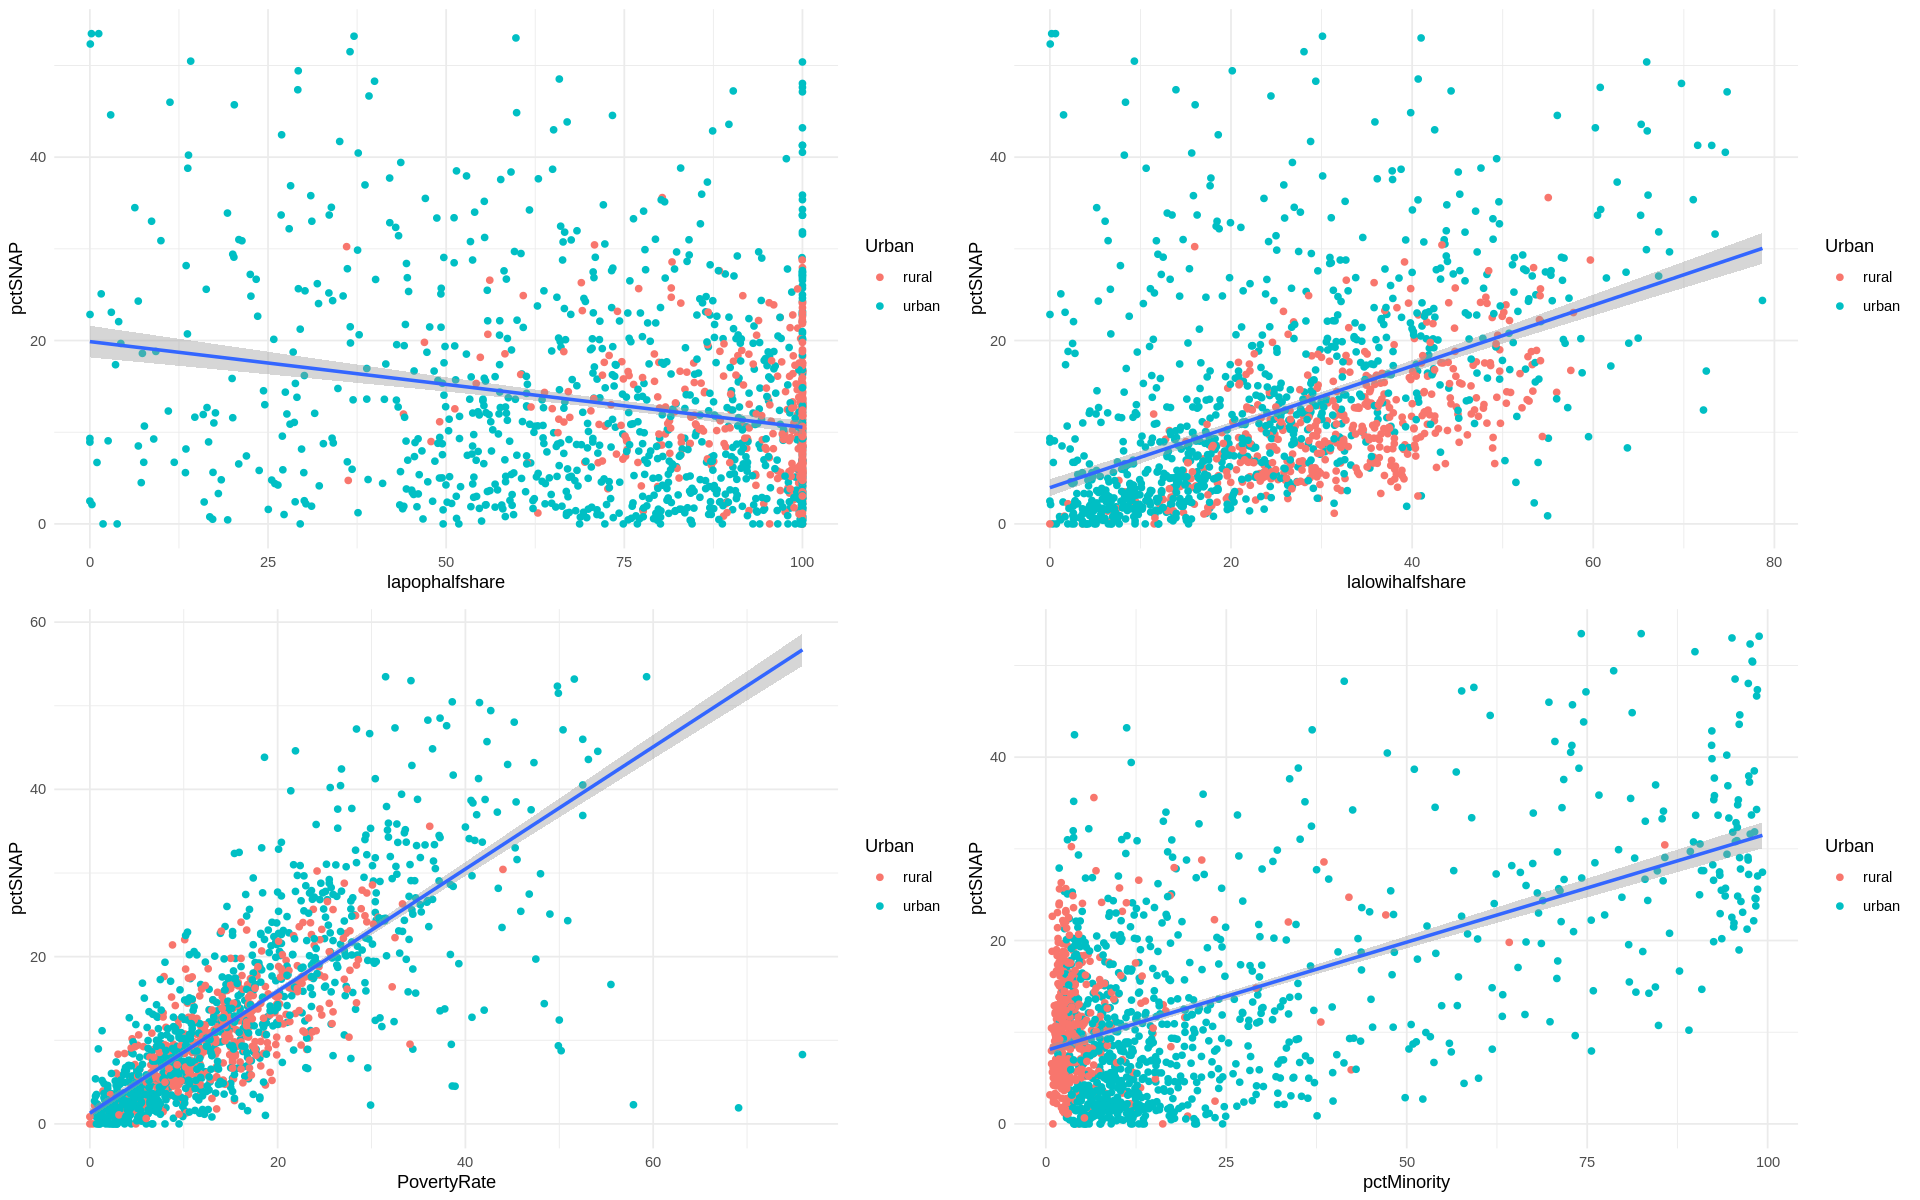

In [69]:
library(gridExtra)
library(repr)
options(repr.plot.width=16, repr.plot.height=10)
grid.arrange(
ggplot(food_access, aes(x=lapophalfshare, y=pctSNAP)) + geom_point(aes(color=Urban))+ geom_smooth(method=lm) + theme_minimal(),
ggplot(food_access, aes(x=lalowihalfshare, y=pctSNAP)) + geom_point(aes(color=Urban))+ geom_smooth(method=lm) + theme_minimal(),
ggplot(food_access, aes(x=PovertyRate, y=pctSNAP)) + geom_point(aes(color=Urban))+ geom_smooth(method=lm) + theme_minimal(),
ggplot(food_access, aes(x=pctMinority, y=pctSNAP)) + geom_point(aes(color=Urban))+ geom_smooth(method=lm) + theme_minimal())

paste('The correlation of lapophalfshare and pctSNAP is',cor(food_access$lapophalfshare, food_access$pctSNAP))
paste('The correlation of lalowihalfshare and pctSNAP is',cor(food_access$lalowihalfshare, food_access$pctSNAP))
paste('The correlation of PovertyRate and pctSNAP is', cor(food_access$PovertyRate, food_access$pctSNAP))
paste('The correlation of pctMinority and pctSNAP is', cor(food_access$pctMinority,food_access$pctSNAP))

As expected from the results of the corrplot, pctSNAP and PovertyRate have the highest correlation at 0.7757. We can see that the points are clustered together in a semi linear way and there are not too many outliers from the line of best fit. pctMinority and PovertyRate have the next best correlation at 0.5946. However, the points seem very clustered in the bottom left side/corner with more outliers from the line of best fit. The third best correlation is lalowihalfshare and pctSNAP at 0.4960. The points are clustered more in the bottom part of the grid, with more spread into other parts of the grid. The last correlation is between lapophalfshare and pctSNAP is the only negative correlation at -0.2272. We see that many of the points are clustered to the bottom right side/corner which differs from the other three plots. This tells us that there are higher amounts of units in tracts that are low access to a supermarket, but not low income. There are distinct clusters of urban/rural points, especially in pctMinority and lalowihalfshare.

In the next few cells, we will create map visuals that can be used to show where areas have higher correlations of pctSNAP, pctMinority, and PovertyRate. We will "zoom-in" to look specifically at the St. Louis and Kansas City Metro areas since they seem to have the most interaction present.

In [70]:
suppressMessages(install.packages("tigris"))
suppressMessages(install.packages("sf"))
library(tigris)
library(sf)

Warning message in install.packages("sf"):
“installation of package ‘s2’ had non-zero exit status”
Warning message in install.packages("sf"):
“installation of package ‘sf’ had non-zero exit status”


In [71]:
mo_census <- tracts("MO", cb=TRUE)
head(mo_census)

Retrieving data for the year 2024

ERROR while rich displaying an object: Error in loadNamespace(name): there is no package called ‘geojsonio’

Traceback:
1. FUN(X[[i]], ...)
2. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
3. tryCatchList(expr, classes, parentenv, handlers)
4. tryCatchOne(expr, names, parentenv, handlers[[1L]])
5. doTryCatch(return(expr), name, parentenv, handler)
6. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler)
7. repr::mime2rep

,STATEFP,COUNTYFP,TRACTCE,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,NAMELSADCO,STATE_NAME,LSAD,ALAND,AWATER,geometry
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<MULTIPOLYGON [°]>
1,29,047,021101,1400000US29047021101,29047021101,211.01,Census Tract 211.01,MO,Clay County,Missouri,CT,4611525,0,MULTIPOLYGON (((-94.58599 3...
2,29,165,030002,1400000US29165030002,29165030002,300.02,Census Tract 300.02,MO,Platte County,Missouri,CT,6042219,205172,MULTIPOLYGON (((-94.62692 3...
3,29,021,000200,1400000US29021000200,29021000200,2,Census Tract 2,MO,Buchanan County,Missouri,CT,6466040,2574,MULTIPOLYGON (((-94.8449 39...
4,29,003,010100,1400000US29003010100,29003010100,101,Census Tract 101,MO,Andrew County,Missouri,CT,170780776,2154491,MULTIPOLYGON (((-94.88097 3...
5,29,001,951000,1400000US29001951000,29001951000,9510,Census Tract 9510,MO,Adair County,Missouri,CT,672409,0,MULTIPOLYGON (((-92.58614 4...
6,29,007,950100,1400000US29007950100,29007950100,9501,Census Tract 9501,MO,Audrain County,Missouri,CT,32573455,129771,MULTIPOLYGON (((-91.55168 3...


In [72]:
mo_census <- left_join(mo_census, food_access, by = c("GEOID"="CensusTract"))
head(mo_census)

ERROR while rich displaying an object: Error in loadNamespace(name): there is no package called ‘geojsonio’

Traceback:
1. FUN(X[[i]], ...)
2. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
3. tryCatchList(expr, classes, parentenv, handlers)
4. tryCatchOne(expr, names, parentenv, handlers[[1L]])
5. doTryCatch(return(expr), name, parentenv, handler)
6. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler)
7. repr::mime2repr[[mime]](obj)
8. repr_geojson.sf(o

STATEFP COUNTYFP TRACTCE GEOIDFQ              GEOID       NAME  
1 29      047      021101  1400000US29047021101 29047021101 211.01
2 29      165      030002  1400000US29165030002 29165030002 300.02
3 29      021      000200  1400000US29021000200 29021000200 2     
4 29      003      010100  1400000US29003010100 29003010100 101   
5 29      001      951000  1400000US29001951000 29001951000 9510  
6 29      007      950100  1400000US29007950100 29007950100 9501  
  NAMELSAD            STUSPS NAMELSADCO      STATE_NAME
1 Census Tract 211.01 MO     Clay County     Missouri  
2 Census Tract 300.02 MO     Platte County   Missouri  
3 Census Tract 2      MO     Buchanan County Missouri  
4 Census Tract 101    MO     Andrew County   Missouri  
5 Census Tract 9510   MO     Adair County    Missouri  
6 Census Tract 9501   MO     Audrain County  Missouri  
  geometry                       ⋯ County          Urban Pop2010 PovertyRate
1 MULTIPOLYGON (((-94.58599 3... ⋯ Clay County     urban 4552    17.2       
2 MULTIPOLYGON (((-94.62692 3... ⋯ Platte County   urban 2828    17.6       
3 MULTIPOLYGON (((-94.8449 39... ⋯ Buchanan County urban 4415     7.0       
4 MULTIPOLYGON (((-94.88097 3... ⋯ Andrew County   rural 5439     5.7       
5 MULTIPOLYGON (((-92.58614 4... ⋯ NA              NA      NA      NA       
6 MULTIPOLYGON (((-91.55168 3... ⋯ Audrain County  urban 4180    16.1       
  MedianFamilyIncome lapophalfshare lalowihalfshare pctMinority pctSNAP
1 62639              30.10          11.25           15.40       16.18  
2 41750              86.79          49.25           24.41       19.30  
3 73688              60.58          13.24            6.48        4.96  
4 93519              98.71          22.72            3.99        2.60  
5    NA                 NA             NA              NA          NA  
6 44425              95.25          45.99           17.34       13.42  
  geometry                      
1 MULTIPOLYGON (((-94.58599 3...
2 MULTIPOLYGON (((-94.62692 3...
3 MULTIPOLYGON (((-94.8449 39...
4 MULTIPOLYGON (((-94.88097 3...
5 MULTIPOLYGON (((-92.58614 4...
6 MULTIPOLYGON (((-91.55168 3...

In [73]:
sapply(mo_census, function(x) sum(is.na(x)))

STATEFP           COUNTYFP            TRACTCE            GEOIDFQ 
                 0                  0                  0                  0 
             GEOID               NAME           NAMELSAD             STUSPS 
                 0                  0                  0                  0 
        NAMELSADCO         STATE_NAME               LSAD              ALAND 
                 0                  0                  0                  0 
            AWATER             County              Urban            Pop2010 
                 0                536                536                536 
       PovertyRate MedianFamilyIncome     lapophalfshare    lalowihalfshare 
               536                536                536                536 
       pctMinority            pctSNAP           geometry 
               536                536                  0

In [74]:
mo_census %>% filter(is.na(County)) %>% filter(NAMELSADCO == 'Stone County')

ERROR while rich displaying an object: Error in loadNamespace(name): there is no package called ‘geojsonio’

Traceback:
1. FUN(X[[i]], ...)
2. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
3. tryCatchList(expr, classes, parentenv, handlers)
4. tryCatchOne(expr, names, parentenv, handlers[[1L]])
5. doTryCatch(return(expr), name, parentenv, handler)
6. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler)
7. repr::mime2repr[[mime]](obj)
8. repr_geojson.sf(o

STATEFP COUNTYFP TRACTCE GEOIDFQ              GEOID       NAME  
1  29      209      090202  1400000US29209090202 29209090202 902.02
2  29      209      090201  1400000US29209090201 29209090201 902.01
3  29      209      090402  1400000US29209090402 29209090402 904.02
4  29      209      090603  1400000US29209090603 29209090603 906.03
5  29      209      090501  1400000US29209090501 29209090501 905.01
6  29      209      090401  1400000US29209090401 29209090401 904.01
7  29      209      090102  1400000US29209090102 29209090102 901.02
8  29      209      090605  1400000US29209090605 29209090605 906.05
9  29      209      090604  1400000US29209090604 29209090604 906.04
10 29      209      090606  1400000US29209090606 29209090606 906.06
11 29      209      090101  1400000US29209090101 29209090101 901.01
12 29      209      090502  1400000US29209090502 29209090502 905.02
   NAMELSAD            STUSPS NAMELSADCO   STATE_NAME
1  Census Tract 902.02 MO     Stone County Missouri  
2  Census Tract 902.01 MO     Stone County Missouri  
3  Census Tract 904.02 MO     Stone County Missouri  
4  Census Tract 906.03 MO     Stone County Missouri  
5  Census Tract 905.01 MO     Stone County Missouri  
6  Census Tract 904.01 MO     Stone County Missouri  
7  Census Tract 901.02 MO     Stone County Missouri  
8  Census Tract 906.05 MO     Stone County Missouri  
9  Census Tract 906.04 MO     Stone County Missouri  
10 Census Tract 906.06 MO     Stone County Missouri  
11 Census Tract 901.01 MO     Stone County Missouri  
12 Census Tract 905.02 MO     Stone County Missouri  
   geometry                       ⋯ County Urban Pop2010 PovertyRate
1  MULTIPOLYGON (((-93.61286 3... ⋯ NA     NA    NA      NA         
2  MULTIPOLYGON (((-93.55152 3... ⋯ NA     NA    NA      NA         
3  MULTIPOLYGON (((-93.49111 3... ⋯ NA     NA    NA      NA         
4  MULTIPOLYGON (((-93.39992 3... ⋯ NA     NA    NA      NA         
5  MULTIPOLYGON (((-93.43094 3... ⋯ NA     NA    NA      NA         
6  MULTIPOLYGON (((-93.58412 3... ⋯ NA     NA    NA      NA         
7  MULTIPOLYGON (((-93.61277 3... ⋯ NA     NA    NA      NA         
8  MULTIPOLYGON (((-93.46392 3... ⋯ NA     NA    NA      NA         
9  MULTIPOLYGON (((-93.40796 3... ⋯ NA     NA    NA      NA         
10 MULTIPOLYGON (((-93.44321 3... ⋯ NA     NA    NA      NA         
11 MULTIPOLYGON (((-93.52416 3... ⋯ NA     NA    NA      NA         
12 MULTIPOLYGON (((-93.49268 3... ⋯ NA     NA    NA      NA         
   MedianFamilyIncome lapophalfshare lalowihalfshare pctMinority pctSNAP
1  NA                 NA             NA              NA          NA     
2  NA                 NA             NA              NA          NA     
3  NA                 NA             NA              NA          NA     
4  NA                 NA             NA              NA          NA     
5  NA                 NA             NA              NA          NA     
6  NA                 NA             NA              NA          NA     
7  NA                 NA             NA              NA          NA     
8  NA                 NA             NA              NA          NA     
9  NA                 NA             NA              NA          NA     
10 NA                 NA             NA              NA          NA     
11 NA                 NA             NA              NA          NA     
12 NA                 NA             NA              NA          NA     
   geometry                      
1  MULTIPOLYGON (((-93.61286 3...
2  MULTIPOLYGON (((-93.55152 3...
3  MULTIPOLYGON (((-93.49111 3...
4  MULTIPOLYGON (((-93.39992 3...
5  MULTIPOLYGON (((-93.43094 3...
6  MULTIPOLYGON (((-93.58412 3...
7  MULTIPOLYGON (((-93.61277 3...
8  MULTIPOLYGON (((-93.46392 3...
9  MULTIPOLYGON (((-93.40796 3...
10 MULTIPOLYGON (((-93.44321 3...
11 MULTIPOLYGON (((-93.52416 3...
12 MULTIPOLYGON (((-93.49268 3...

In [75]:
food_access %>% filter(County == 'Stone County')

CensusTract,County,Urban,Pop2010,PovertyRate,MedianFamilyIncome,lapophalfshare,lalowihalfshare,pctMinority,pctSNAP
<chr>,<chr>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
29209090100,Stone County,rural,7480,12.0,60333,89.84,28.70,2.07,10.47
29209090200,Stone County,rural,4950,14.4,44988,100.00,42.50,2.51,11.76
29209090400,Stone County,rural,5399,8.4,55276,100.00,35.71,2.50,6.64
29209090500,Stone County,urban,5778,7.1,64459,94.90,27.77,2.42,9.28
29209090601,Stone County,rural,3381,3.1,69102,99.52,17.01,2.96,1.08
29209090602,Stone County,rural,5214,27.1,48993,98.95,46.74,4.60,17.30


It was unclear why so many NA's were being introduced when joining the two sets until realizing that the mo_census is using 2024 tracts and food_access is using 2010 tracts. Used Stone County to compare the amount of tracts since there was an NA in Stone County. Pulling the 2010 tracts data should fix this problem.

In [76]:
mo_2010 <- tracts("MO", cb=TRUE, year = 2010) 

In [77]:
#split the geo_id so that it matches the format in food_access
mo_2010$GEO_ID <- sub(".*US", "", mo_2010$GEO_ID)
head(mo_2010)

ERROR while rich displaying an object: Error in loadNamespace(name): there is no package called ‘geojsonio’

Traceback:
1. FUN(X[[i]], ...)
2. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
3. tryCatchList(expr, classes, parentenv, handlers)
4. tryCatchOne(expr, names, parentenv, handlers[[1L]])
5. doTryCatch(return(expr), name, parentenv, handler)
6. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler)
7. repr::mime2repr[[mime]](obj)
8. repr_geojson.sf(o

,GEO_ID,STATE,COUNTY,TRACT,NAME,LSAD,CENSUSAREA,geometry,COUNTYFP,STATEFP
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<MULTIPOLYGON [°]>,<chr>,<chr>
1,29095015000,29,095,015000,150,Tract,54.265,MULTIPOLYGON (((-94.19707 3...,095,29
2,29095015700,29,095,015700,157,Tract,0.390,MULTIPOLYGON (((-94.5834 39...,095,29
3,29095016200,29,095,016200,162,Tract,0.495,MULTIPOLYGON (((-94.57105 3...,095,29
4,29095016400,29,095,016400,164,Tract,0.496,MULTIPOLYGON (((-94.51594 3...,095,29
5,29095016900,29,095,016900,169,Tract,0.495,MULTIPOLYGON (((-94.56174 3...,095,29
6,29095017800,29,095,017800,178,Tract,0.470,MULTIPOLYGON (((-94.5789 39...,095,29


In [78]:
#check the same Stone County tracts we pulled earlier for food_access
mo_2010 %>% filter(COUNTY == '209')

ERROR while rich displaying an object: Error in loadNamespace(name): there is no package called ‘geojsonio’

Traceback:
1. FUN(X[[i]], ...)
2. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
3. tryCatchList(expr, classes, parentenv, handlers)
4. tryCatchOne(expr, names, parentenv, handlers[[1L]])
5. doTryCatch(return(expr), name, parentenv, handler)
6. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler)
7. repr::mime2repr[[mime]](obj)
8. repr_geojson.sf(o

,GEO_ID,STATE,COUNTY,TRACT,NAME,LSAD,CENSUSAREA,geometry,COUNTYFP,STATEFP
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<MULTIPOLYGON [°]>,<chr>,<chr>
1,29209090100,29,209,090100,901,Tract,175.334,MULTIPOLYGON (((-93.34759 3...,209,29
2,29209090400,29,209,090400,904,Tract,86.092,MULTIPOLYGON (((-93.47771 3...,209,29
3,29209090500,29,209,090500,905,Tract,14.849,MULTIPOLYGON (((-93.47608 3...,209,29
4,29209090601,29,209,090601,906.01,Tract,21.007,MULTIPOLYGON (((-93.34363 3...,209,29
5,29209090602,29,209,090602,906.02,Tract,67.191,MULTIPOLYGON (((-93.39993 3...,209,29
6,29209090200,29,209,090200,902,Tract,99.561,MULTIPOLYGON (((-93.51351 3...,209,29


In [79]:
#join mo_2010 with food_access so we can call food_access variables in our plot
mo_2010 <- left_join(mo_2010, food_access, by = c("GEO_ID"="CensusTract"))
head(mo_2010)

ERROR while rich displaying an object: Error in loadNamespace(name): there is no package called ‘geojsonio’

Traceback:
1. FUN(X[[i]], ...)
2. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
3. tryCatchList(expr, classes, parentenv, handlers)
4. tryCatchOne(expr, names, parentenv, handlers[[1L]])
5. doTryCatch(return(expr), name, parentenv, handler)
6. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler)
7. repr::mime2repr[[mime]](obj)
8. repr_geojson.sf(o

,GEO_ID,STATE,COUNTY,TRACT,NAME,LSAD,CENSUSAREA,COUNTYFP,STATEFP,County,Urban,Pop2010,PovertyRate,MedianFamilyIncome,lapophalfshare,lalowihalfshare,pctMinority,pctSNAP,geometry
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<MULTIPOLYGON [°]>
1,29095015000,29,095,015000,150,Tract,54.265,095,29,Jackson County,rural,3741,7.9,77917,79.68,14.40,4.83,4.08,MULTIPOLYGON (((-94.19707 3...
2,29095015700,29,095,015700,157,Tract,0.390,095,29,NA,NA,NA,NA,NA,NA,NA,NA,NA,MULTIPOLYGON (((-94.5834 39...
3,29095016200,29,095,016200,162,Tract,0.495,095,29,Jackson County,urban,1155,29.0,48661,100.00,50.70,86.41,20.79,MULTIPOLYGON (((-94.57105 3...
4,29095016400,29,095,016400,164,Tract,0.496,095,29,Jackson County,urban,1873,48.0,25100,77.90,65.87,79.35,29.91,MULTIPOLYGON (((-94.51594 3...
5,29095016900,29,095,016900,169,Tract,0.495,095,29,Jackson County,urban,2367,25.7,42760,87.05,51.08,92.40,28.26,MULTIPOLYGON (((-94.56174 3...
6,29095017800,29,095,017800,178,Tract,0.470,095,29,Jackson County,urban,2933,27.1,46403,13.69,6.73,58.43,20.72,MULTIPOLYGON (((-94.5789 39...


In [80]:
#filter for St. Louis City and County
mo_2010_sc <-mo_2010 %>%
filter(County == 'St. Louis city'| County == 'St. Louis County')
head(mo_2010_sc)

ERROR while rich displaying an object: Error in loadNamespace(name): there is no package called ‘geojsonio’

Traceback:
1. FUN(X[[i]], ...)
2. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
3. tryCatchList(expr, classes, parentenv, handlers)
4. tryCatchOne(expr, names, parentenv, handlers[[1L]])
5. doTryCatch(return(expr), name, parentenv, handler)
6. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler)
7. repr::mime2repr[[mime]](obj)
8. repr_geojson.sf(o

,GEO_ID,STATE,COUNTY,TRACT,NAME,LSAD,CENSUSAREA,COUNTYFP,STATEFP,County,Urban,Pop2010,PovertyRate,MedianFamilyIncome,lapophalfshare,lalowihalfshare,pctMinority,pctSNAP,geometry
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<MULTIPOLYGON [°]>
1,29189219300,29,189,219300,2193,Tract,0.723,189,29,St. Louis County,urban,2039,1.8,140583,17.23,1.14,13.53,0.51,MULTIPOLYGON (((-90.35974 3...
2,29189219400,29,189,219400,2194,Tract,1.527,189,29,St. Louis County,urban,5964,0.9,128413,29.52,1.98,4.00,0.00,MULTIPOLYGON (((-90.36812 3...
3,29189219700,29,189,219700,2197,Tract,1.712,189,29,St. Louis County,urban,5964,11.7,82436,87.34,22.66,9.15,6.84,MULTIPOLYGON (((-90.33238 3...
4,29189220432,29,189,220432,2204.32,Tract,3.286,189,29,St. Louis County,urban,8049,3.5,87614,99.99,15.51,4.36,2.39,MULTIPOLYGON (((-90.32788 3...
5,29189220446,29,189,220446,2204.46,Tract,1.341,189,29,St. Louis County,urban,4584,3.8,101902,100.00,13.92,2.87,0.67,MULTIPOLYGON (((-90.32552 3...
6,29189220702,29,189,220702,2207.02,Tract,0.788,189,29,St. Louis County,urban,3653,4.0,82909,57.95,9.12,3.73,1.64,MULTIPOLYGON (((-90.36141 3...


In [81]:
#filter for counties that make up Kansas City Metro area according to the Kansas City wikipedia page
mo_2010_ks <- mo_2010 %>%
filter(County == 'Jackson County'| County == 'Clay County'| County == 'Platte County' | County == 'Cass County')
head(mo_2010_ks)

ERROR while rich displaying an object: Error in loadNamespace(name): there is no package called ‘geojsonio’

Traceback:
1. FUN(X[[i]], ...)
2. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
3. tryCatchList(expr, classes, parentenv, handlers)
4. tryCatchOne(expr, names, parentenv, handlers[[1L]])
5. doTryCatch(return(expr), name, parentenv, handler)
6. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler)
7. repr::mime2repr[[mime]](obj)
8. repr_geojson.sf(o

,GEO_ID,STATE,COUNTY,TRACT,NAME,LSAD,CENSUSAREA,COUNTYFP,STATEFP,County,Urban,Pop2010,PovertyRate,MedianFamilyIncome,lapophalfshare,lalowihalfshare,pctMinority,pctSNAP,geometry
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<MULTIPOLYGON [°]>
1,29095015000,29,095,015000,150,Tract,54.265,095,29,Jackson County,rural,3741,7.9,77917,79.68,14.40,4.83,4.08,MULTIPOLYGON (((-94.19707 3...
2,29095016200,29,095,016200,162,Tract,0.495,095,29,Jackson County,urban,1155,29.0,48661,100.00,50.70,86.41,20.79,MULTIPOLYGON (((-94.57105 3...
3,29095016400,29,095,016400,164,Tract,0.496,095,29,Jackson County,urban,1873,48.0,25100,77.90,65.87,79.35,29.91,MULTIPOLYGON (((-94.51594 3...
4,29095016900,29,095,016900,169,Tract,0.495,095,29,Jackson County,urban,2367,25.7,42760,87.05,51.08,92.40,28.26,MULTIPOLYGON (((-94.56174 3...
5,29095017800,29,095,017800,178,Tract,0.470,095,29,Jackson County,urban,2933,27.1,46403,13.69,6.73,58.43,20.72,MULTIPOLYGON (((-94.5789 39...
6,29095018100,29,095,018100,181,Tract,7.171,095,29,Jackson County,urban,6643,3.8,125576,76.11,4.38,14.79,1.93,MULTIPOLYGON (((-94.45503 3...


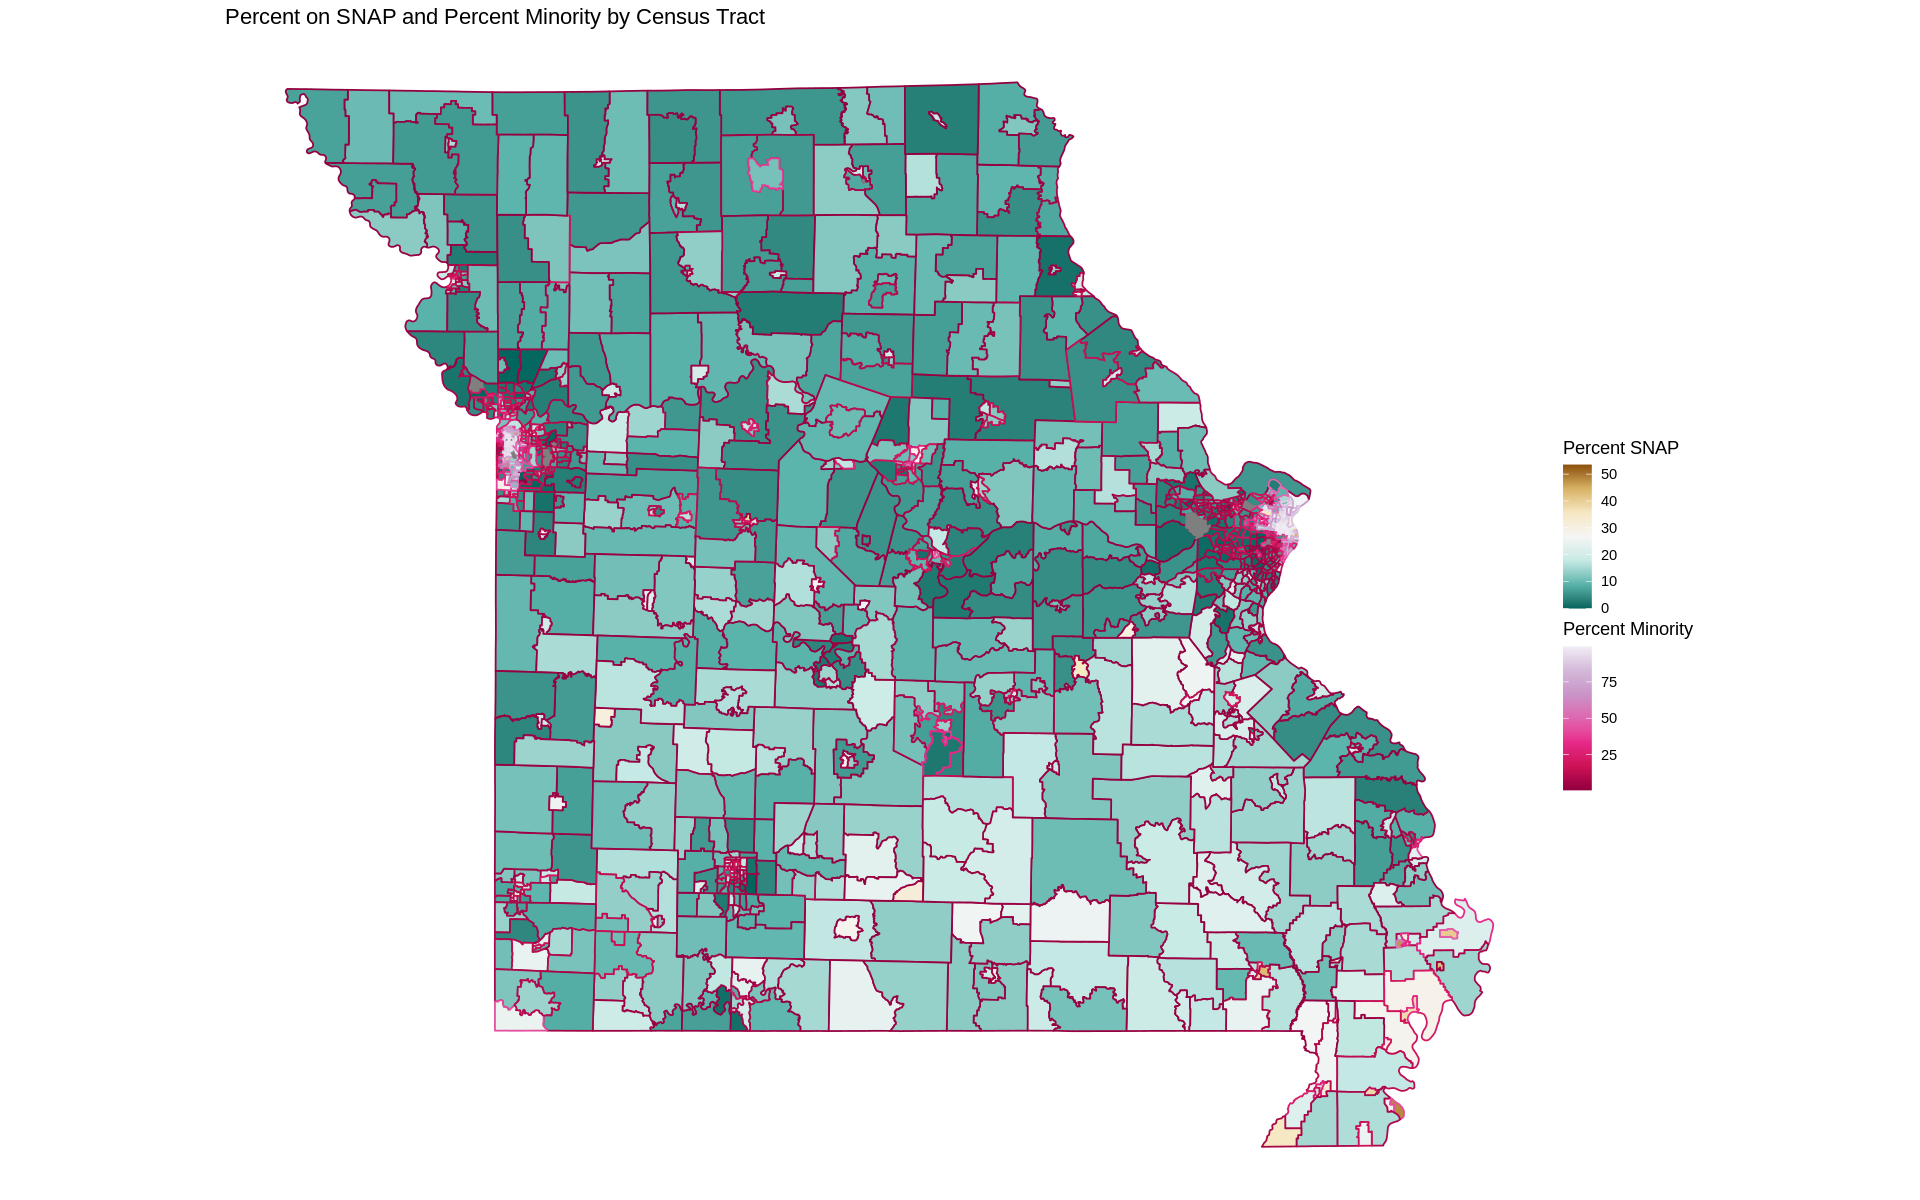

In [82]:
ggplot(data=mo_2010) + geom_sf(aes(fill = pctSNAP, color = pctMinority)) + 
scale_fill_distiller(palette = "BrBG") + scale_color_distiller(palette = "PuRd") + 
theme_void() + theme(axis.ticks = element_blank()) + labs(title = "Percent on SNAP and Percent Minority by Census Tract", color = 'Percent Minority', fill = 'Percent SNAP')

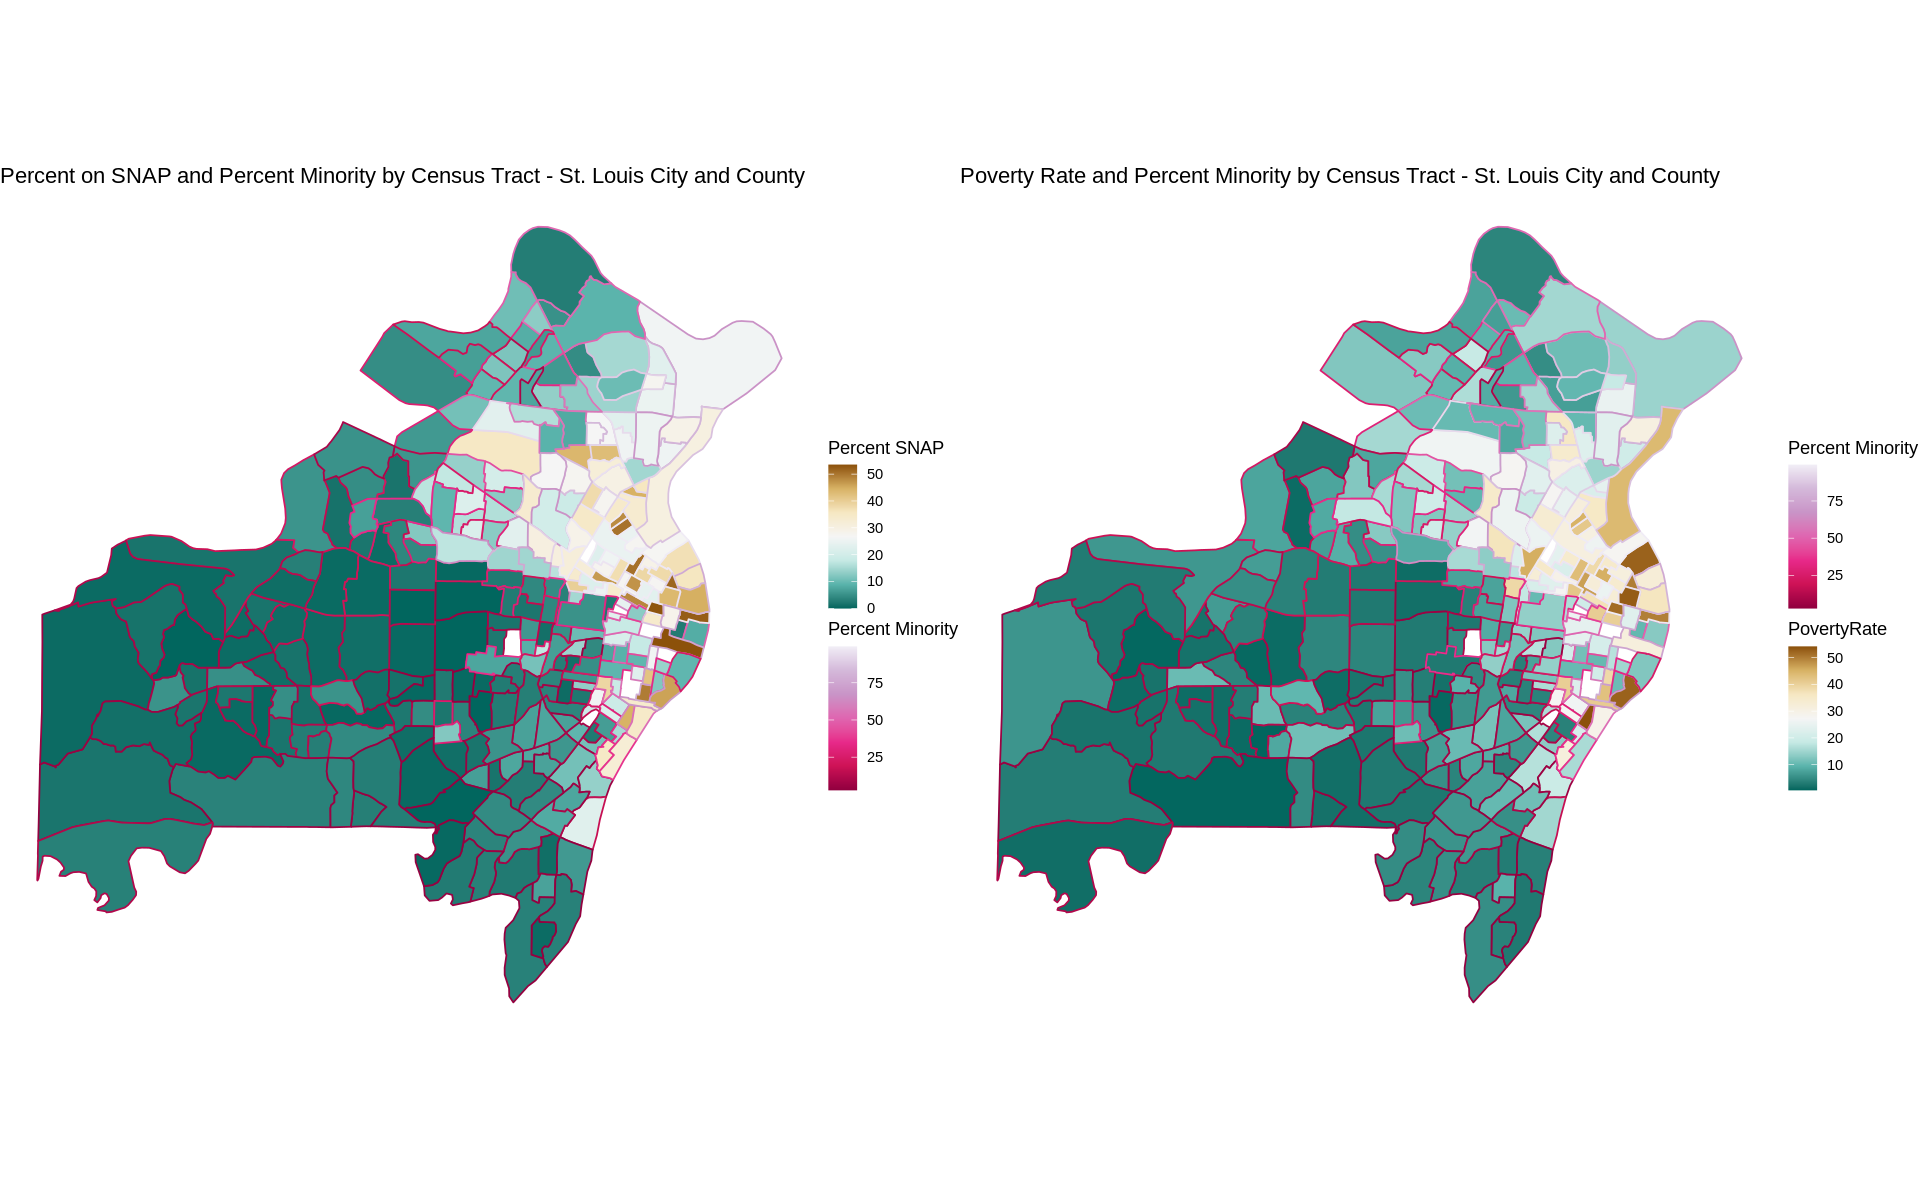

In [83]:
grid.arrange(
    ggplot(data=mo_2010_sc) + geom_sf(aes(fill = pctSNAP, color = pctMinority)) + 
    scale_fill_distiller(palette = "BrBG") + scale_color_distiller(palette = "PuRd") + 
    theme_void() + theme(axis.ticks = element_blank()) + 
    labs(title = "Percent on SNAP and Percent Minority by Census Tract - St. Louis City and County", 
         color = 'Percent Minority', fill = 'Percent SNAP'),
    ggplot(data=mo_2010_sc) + geom_sf(aes(fill = PovertyRate, color = pctMinority)) + 
    scale_fill_distiller(palette = "BrBG") + scale_color_distiller(palette = "PuRd") + 
    theme_void() + theme(axis.ticks = element_blank()) +
    labs(title = "Poverty Rate and Percent Minority by Census Tract - St. Louis City and County", 
         color = 'Percent Minority', fill = 'PovertyRate'), ncol = 2)

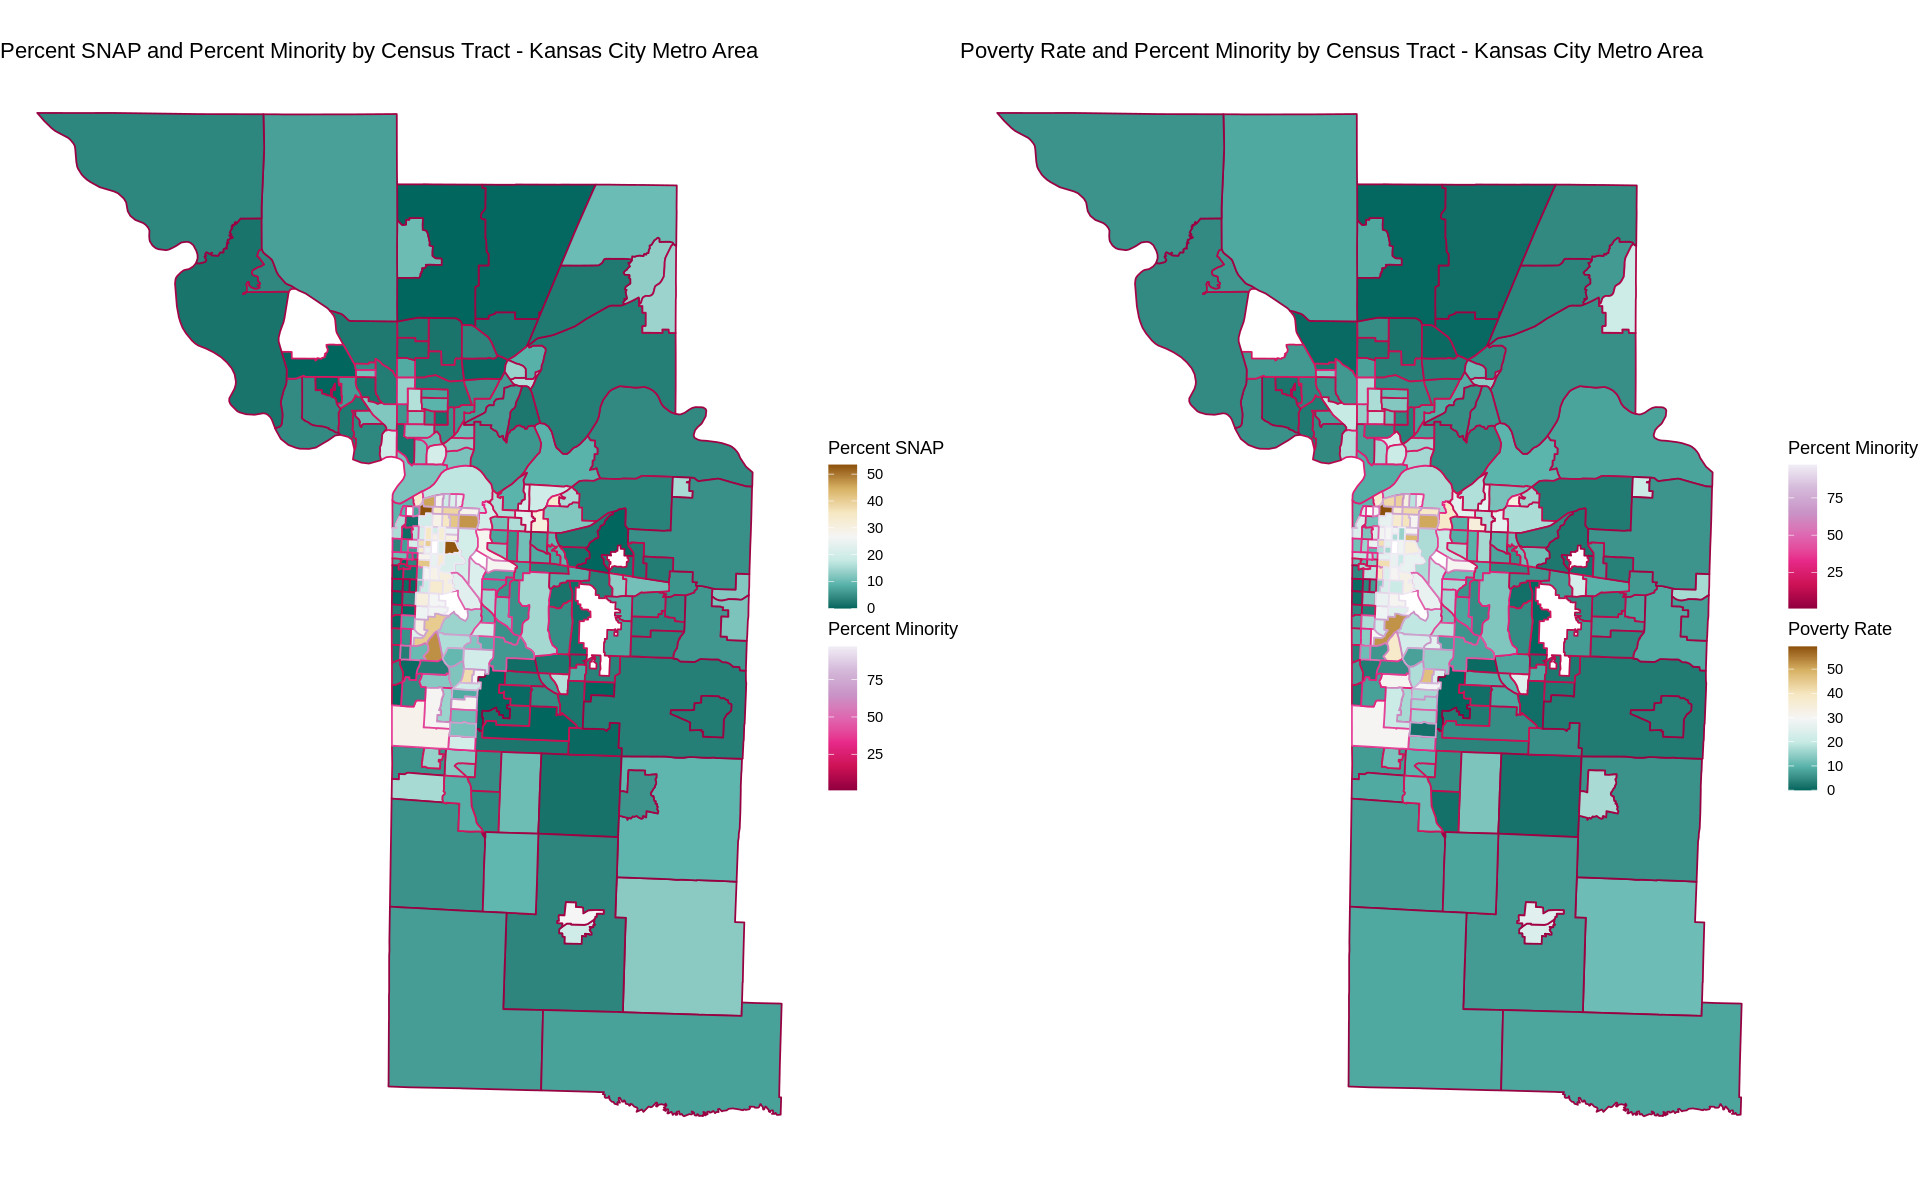

In [84]:
grid.arrange(
    ggplot(data=mo_2010_ks) + geom_sf(aes(fill = pctSNAP, color = pctMinority)) + 
    scale_fill_distiller(palette = "BrBG") + scale_color_distiller(palette = "PuRd") + 
    theme_void() + theme(axis.ticks = element_blank())+
    labs(title = "Percent SNAP and Percent Minority by Census Tract - Kansas City Metro Area", 
         color = 'Percent Minority', fill = 'Percent SNAP'),
    ggplot(data=mo_2010_ks) + geom_sf(aes(fill = PovertyRate, color = pctMinority)) + 
    scale_fill_distiller(palette = "BrBG") + scale_color_distiller(palette = "PuRd") + 
    theme_void() + theme(axis.ticks = element_blank()) + 
    labs(title = "Poverty Rate and Percent Minority by Census Tract - Kansas City Metro Area", 
         color = 'Percent Minority', fill = 'Poverty Rate'), ncol=2)

The plots show that areas with higher percent SNAP also have a higher Poverty Rate.  Additionally, areas with higher percentages of minorities have higher percent SNAP and Poverty Rates.

## 3. Feature Engineering 

 - Any PCA, FA, feature selection, feature ranking, etc. 
 
 - Rank features by things like random forest feature importance, regression p-values, etc. 
 
 

We have to standardize our variables to hopefully reduce variance when running PCA tests. We do this by using scale() and selecting all variables that are not a factor or character.

In [85]:
standard_fa <- as.data.frame(scale(food_access[!sapply(food_access, class)%in%c('factor', 'character')]))
head(standard_fa)

,Pop2010,PovertyRate,MedianFamilyIncome,lapophalfshare,lalowihalfshare,pctMinority,pctSNAP
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,-0.3028826,-0.19120374,-0.3717301,0.8447010,0.6005290,-0.6943161,-0.59096884
2,-0.7424703,-0.02596032,-0.1993908,0.9036104,0.5803112,-0.7020713,0.01855587
3,-0.7806465,2.17728535,-0.5372048,-0.2793865,1.0224946,-0.4841509,0.63490725
4,-0.2523553,0.27698596,-0.2685887,-0.2060503,0.0566043,-0.5679068,-0.19502159
5,1.5368733,1.12156347,0.4008301,0.9036104,1.1027137,-0.5016001,-0.47101437
6,-1.1590400,3.17792609,-0.8923700,-1.7905929,0.1511715,-0.4593344,-0.38031710


In [86]:
#run the pca test using prcomp(), this will tell us the importance of our components
#remove pctSNAP since this is the variable we want to predict with our model
fa_pca <- prcomp(standard_fa[,-11])
summary(fa_pca)

Importance of components:
                          PC1    PC2    PC3     PC4     PC5     PC6     PC7
Standard deviation     1.8233 1.2571 0.9366 0.78789 0.53318 0.45557 0.32477
Proportion of Variance 0.4749 0.2258 0.1253 0.08868 0.04061 0.02965 0.01507
Cumulative Proportion  0.4749 0.7007 0.8260 0.91467 0.95528 0.98493 1.00000

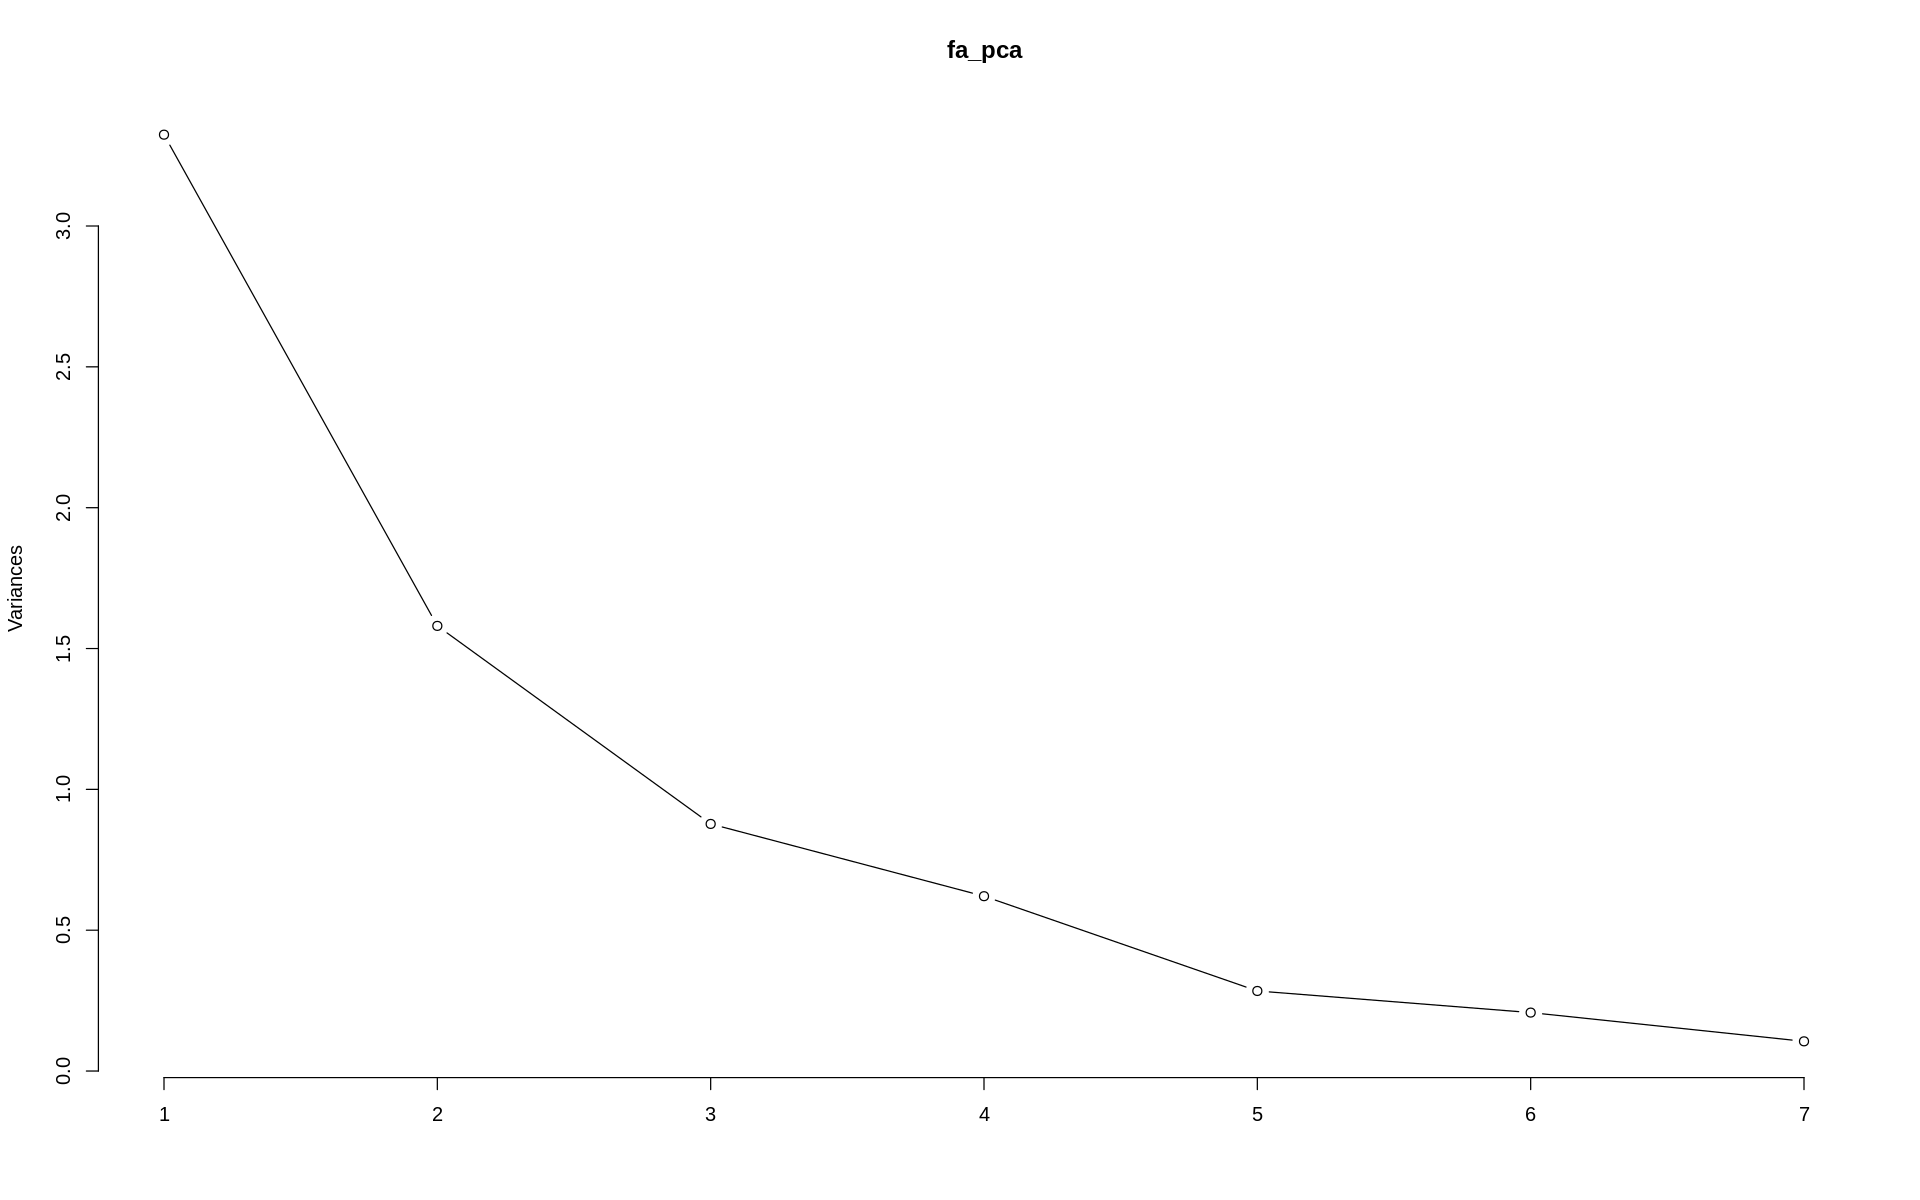

In [87]:
#use a scree plot to visualize our components and their variances
screeplot(fa_pca, type="lines")

In [88]:
#find the variance to use Kaiser's criterion which says we should only keep components with variance > 1
(fa_pca$sdev)^2

[1] 3.3242746 1.5803605 0.8772978 0.6207664 0.2842768 0.2075480 0.1054758

Now that we have run our PCA test and examined our Scree plot and used Kaiser's criterion, we should be able to fit a multiple regression model using just our first two components. We can then compare this model to the one we will create later using our key variables to predict pctSNAP.

In [89]:
fit <- lm(food_access$pctSNAP ~ fa_pca$x[,1] + fa_pca$x[,2])
summary(fit)


Call:
lm(formula = food_access$pctSNAP ~ fa_pca$x[, 1] + fa_pca$x[, 
    2])

Residuals:
     Min       1Q   Median       3Q      Max 
-24.4477  -2.6196  -0.0156   2.4438  18.6089 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)   12.64973    0.11627 108.792   <2e-16 ***
fa_pca$x[, 1] -5.07177    0.06380 -79.500   <2e-16 ***
fa_pca$x[, 2]  0.84337    0.09253   9.115   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 4.305 on 1368 degrees of freedom
Multiple R-squared:  0.824,	Adjusted R-squared:  0.8237 
F-statistic:  3202 on 2 and 1368 DF,  p-value: < 2.2e-16


The R-squared of our above model is 0.824, so it can explain 82.4% of the variance. An ideal model would have an R-squared value as close to 1 as possible, so 0.824 is pretty good. Additionally, our p-value is less than 0.05, so we can assume that our variables are able to help predict new values.

We can also use a random forest to look at specific variables and their importance, but we have to first split our data into testing and training sets. We will do this using the sample.split() function. We will create correlation plots for our testing and training sets to see if they align with food_access.

In [90]:
library(caTools)
set.seed(600)

split = sample.split(food_access$pctSNAP, SplitRatio = 0.7)
train_data = subset(food_access[,4:10], split == TRUE)
test_data = subset(food_access[,4:10], split == FALSE)

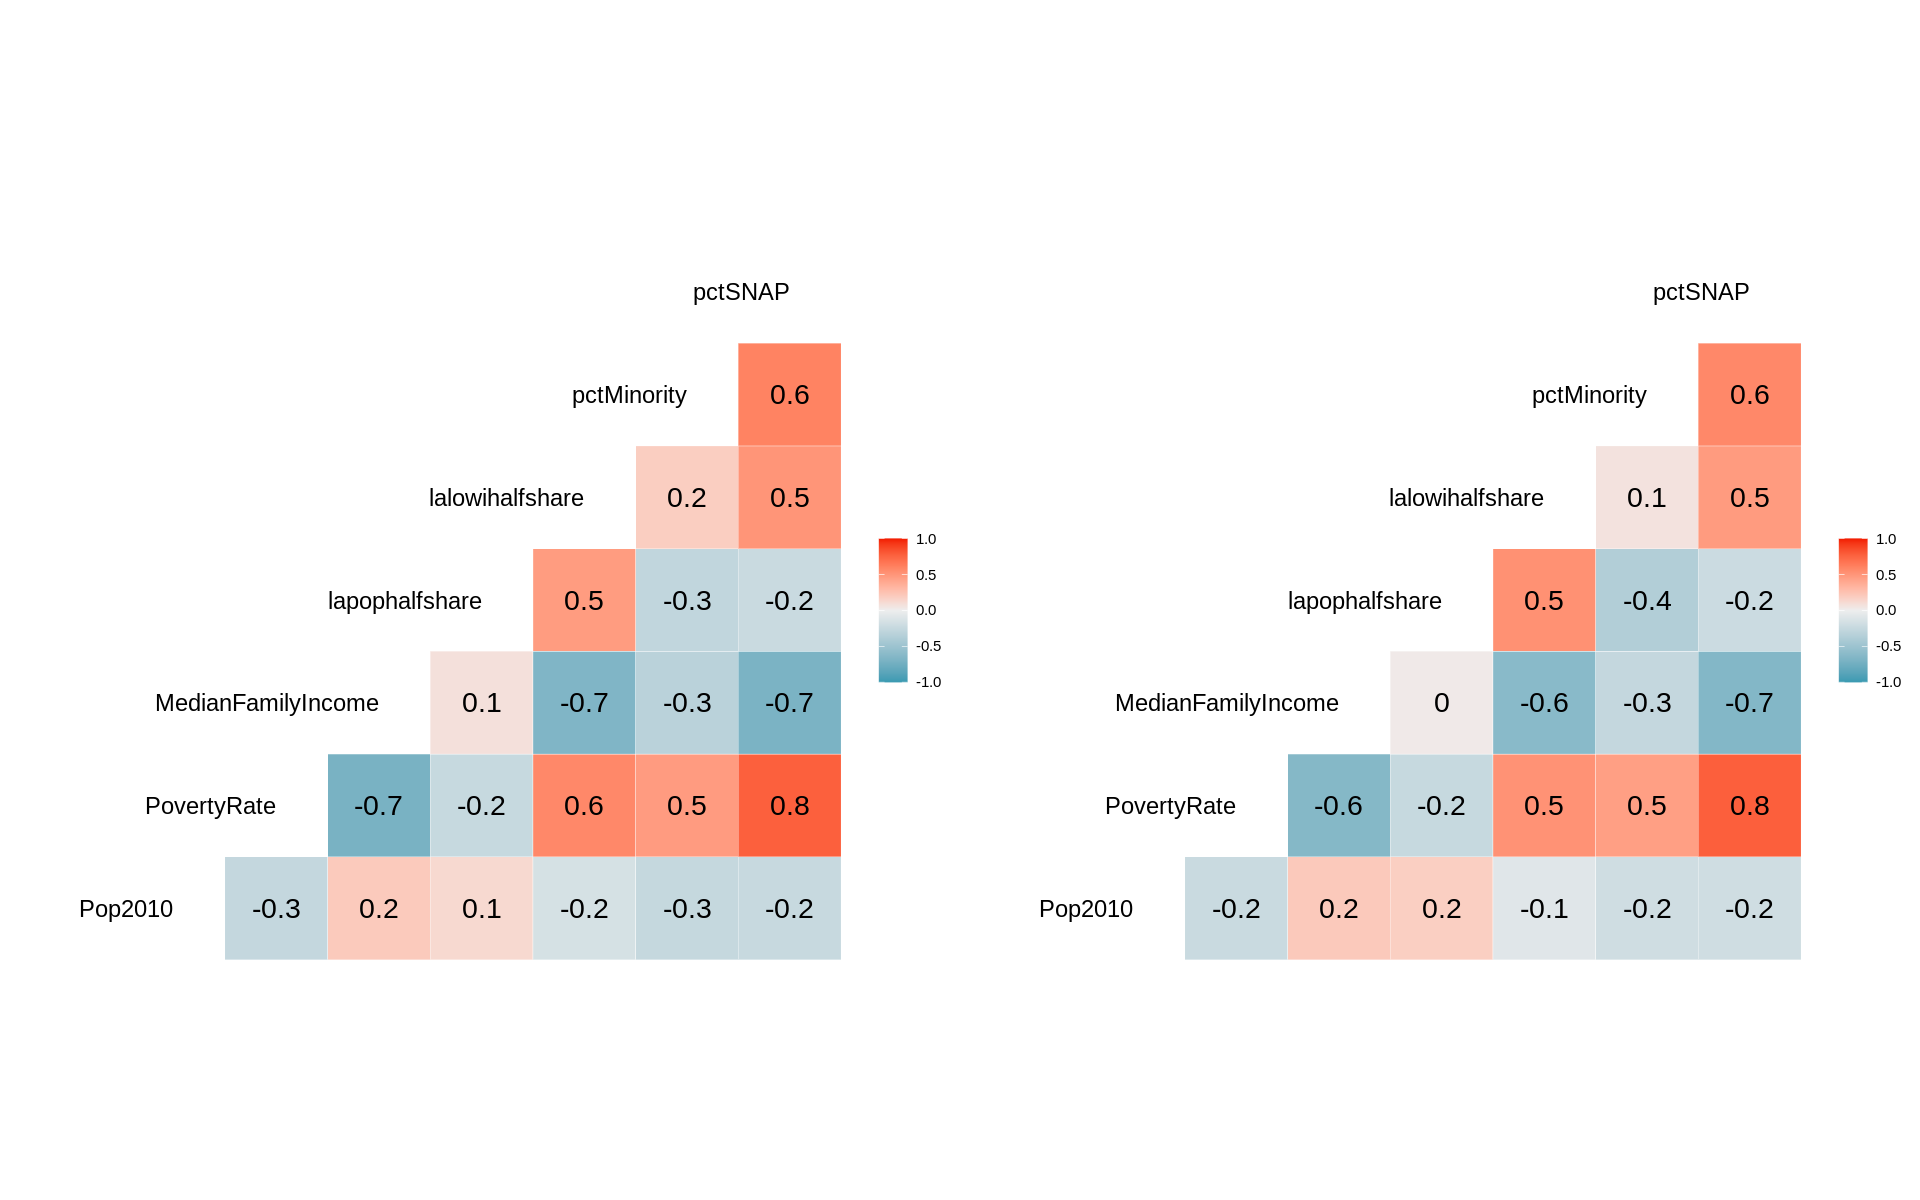

In [95]:
grid.arrange(ggcorr(train_data, label = TRUE ,label_size=6, hjust=1, size = 5, layout.exp = 1),
             ggcorr(test_data, label = TRUE ,label_size=6, hjust=1, size = 5, layout.exp = 1),
             ncol=2)

In [92]:
library(randomForest)

randomForest 4.6-14

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:gridExtra’:

    combine


The following object is masked from ‘package:ggplot2’:

    margin


The following object is masked from ‘package:dplyr’:

    combine





Call:
 randomForest(formula = pctSNAP ~ ., data = train_data, method = "class",      importance = TRUE) 
               Type of random forest: regression
                     Number of trees: 500
No. of variables tried at each split: 2

          Mean of squared residuals: 25.15713
                    % Var explained: 76.88


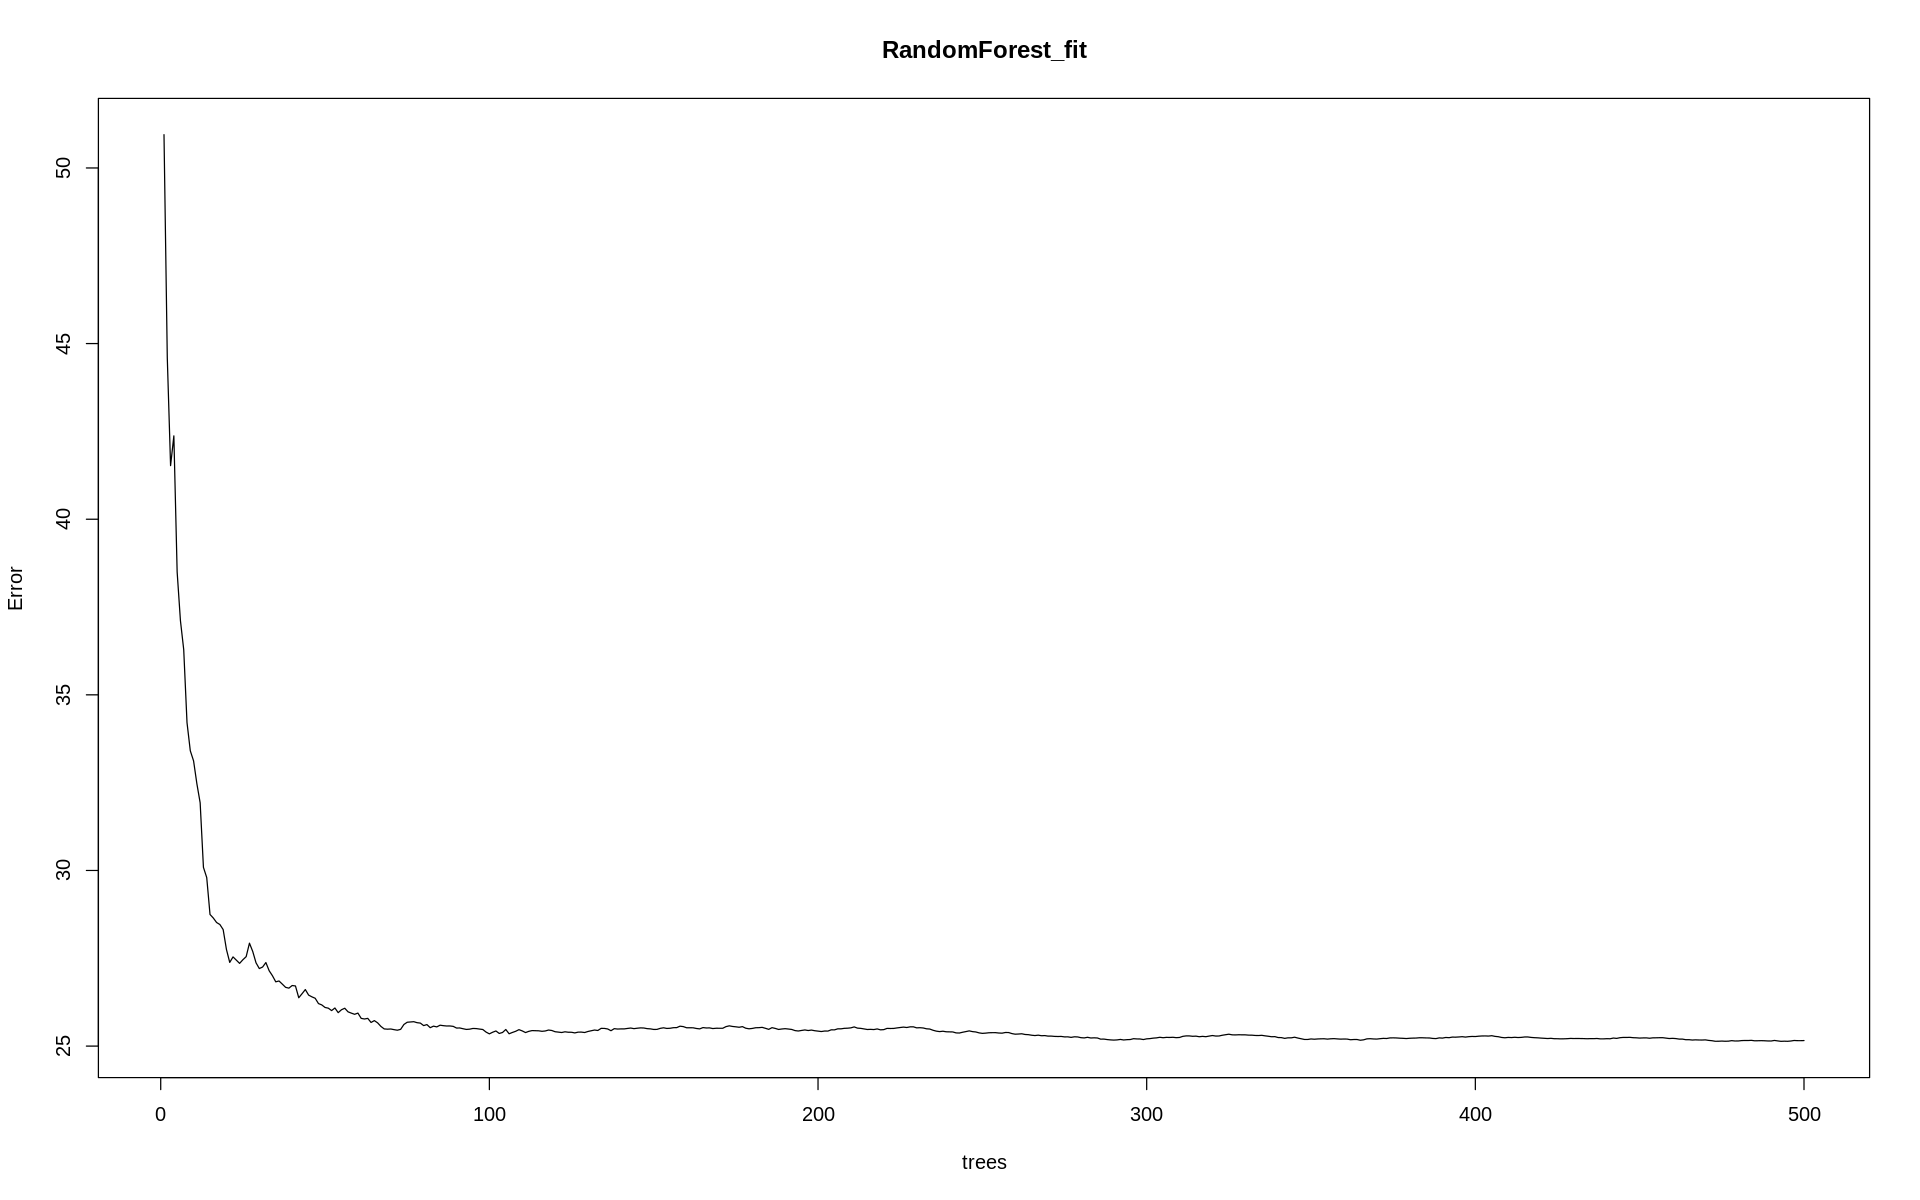

In [93]:
RandomForest_fit <- randomForest(pctSNAP~.,method="class",data=train_data,importance = TRUE) 


plot(RandomForest_fit)
print(RandomForest_fit)

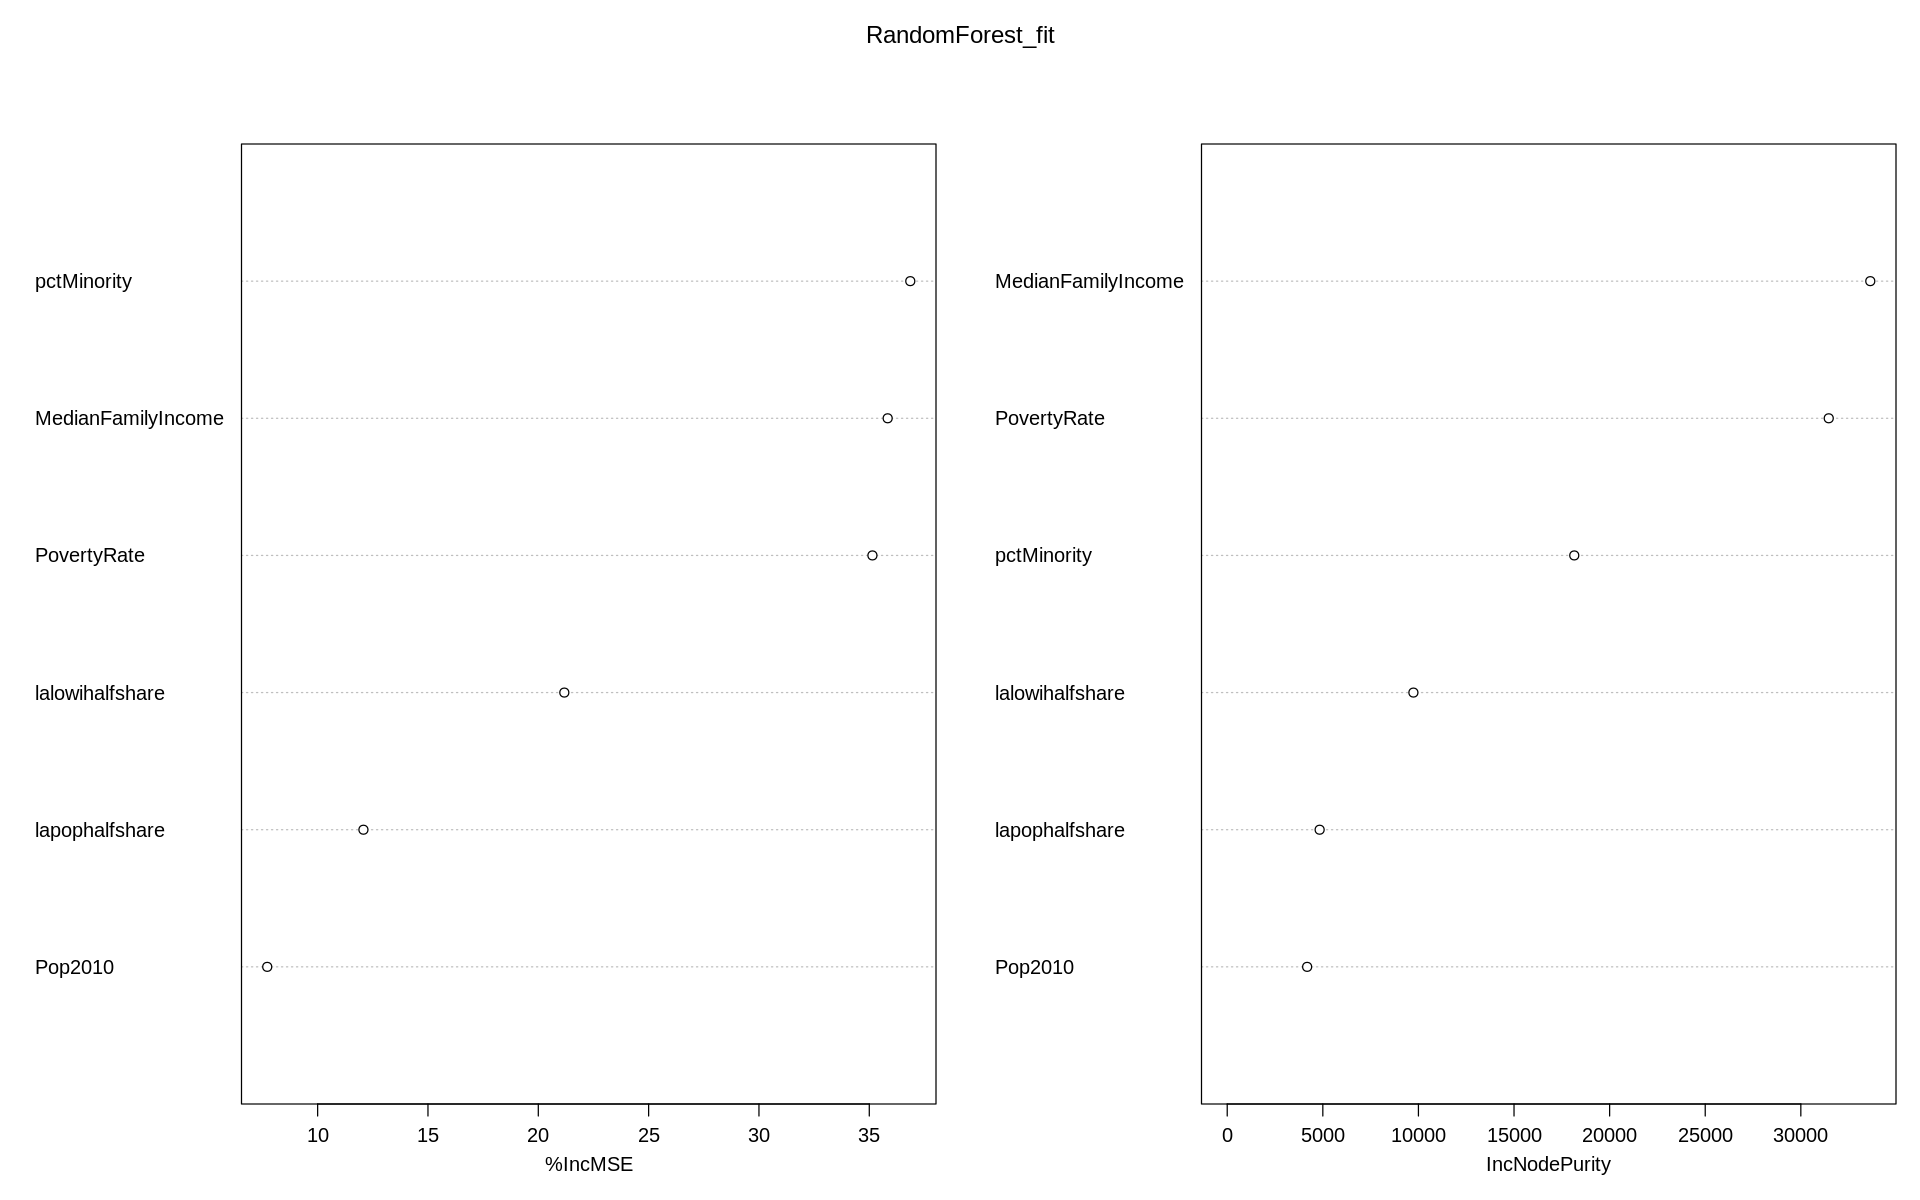

In [94]:
varImpPlot(RandomForest_fit)

According to the IncNodePurity plot, MedianFamilyIncome is ranked the most important for modeling pctSNAP. This is not surprising since SNAP is distributed based on income. Because of this, we are going to disregard MedianFamilyIncome in our future models to see how well we can fit a model without it. Our two next important variables are PovertyRate and pctMinority, which is good because they are the two variables we are most interested in. We are looking to see how well they can predict pctSNAP. After them follow lalowihalfshare and lapophalfshare which we will also use in our model to see how low-income and low-access can effect SNAP.

## 4. 5. ... The Rest..

Similar to above, have **sections** for every major step in your analysis: hypotheses testing, modeling, running your models (training, testing), finding better parameters for models, **interpreting results**, show evaluation measures such as R^2, AIC, FP, FN, accuracy, MSE, **confusion matrices**, ROC, etc. 



First, let us look just at the relationship between percent on SNAP and poverty rate. Since pctSNAP and PovertyRate have the highest correlation, PovertyRate should be able to give us a good starting point for our model. We will look at the summary and residual plots to see how our model performed. 

In [96]:
fit1 <- lm(pctSNAP ~ PovertyRate ,data=train_data)
summary(fit1)


Call:
lm(formula = pctSNAP ~ PovertyRate, data = train_data)

Residuals:
    Min      1Q  Median      3Q     Max 
-49.507  -2.942  -0.701   2.484  29.264 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   1.4002     0.3663   3.822 0.000141 ***
PovertyRate   0.7240     0.0191  37.911  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 6.601 on 957 degrees of freedom
Multiple R-squared:  0.6003,	Adjusted R-squared:  0.5999 
F-statistic:  1437 on 1 and 957 DF,  p-value: < 2.2e-16


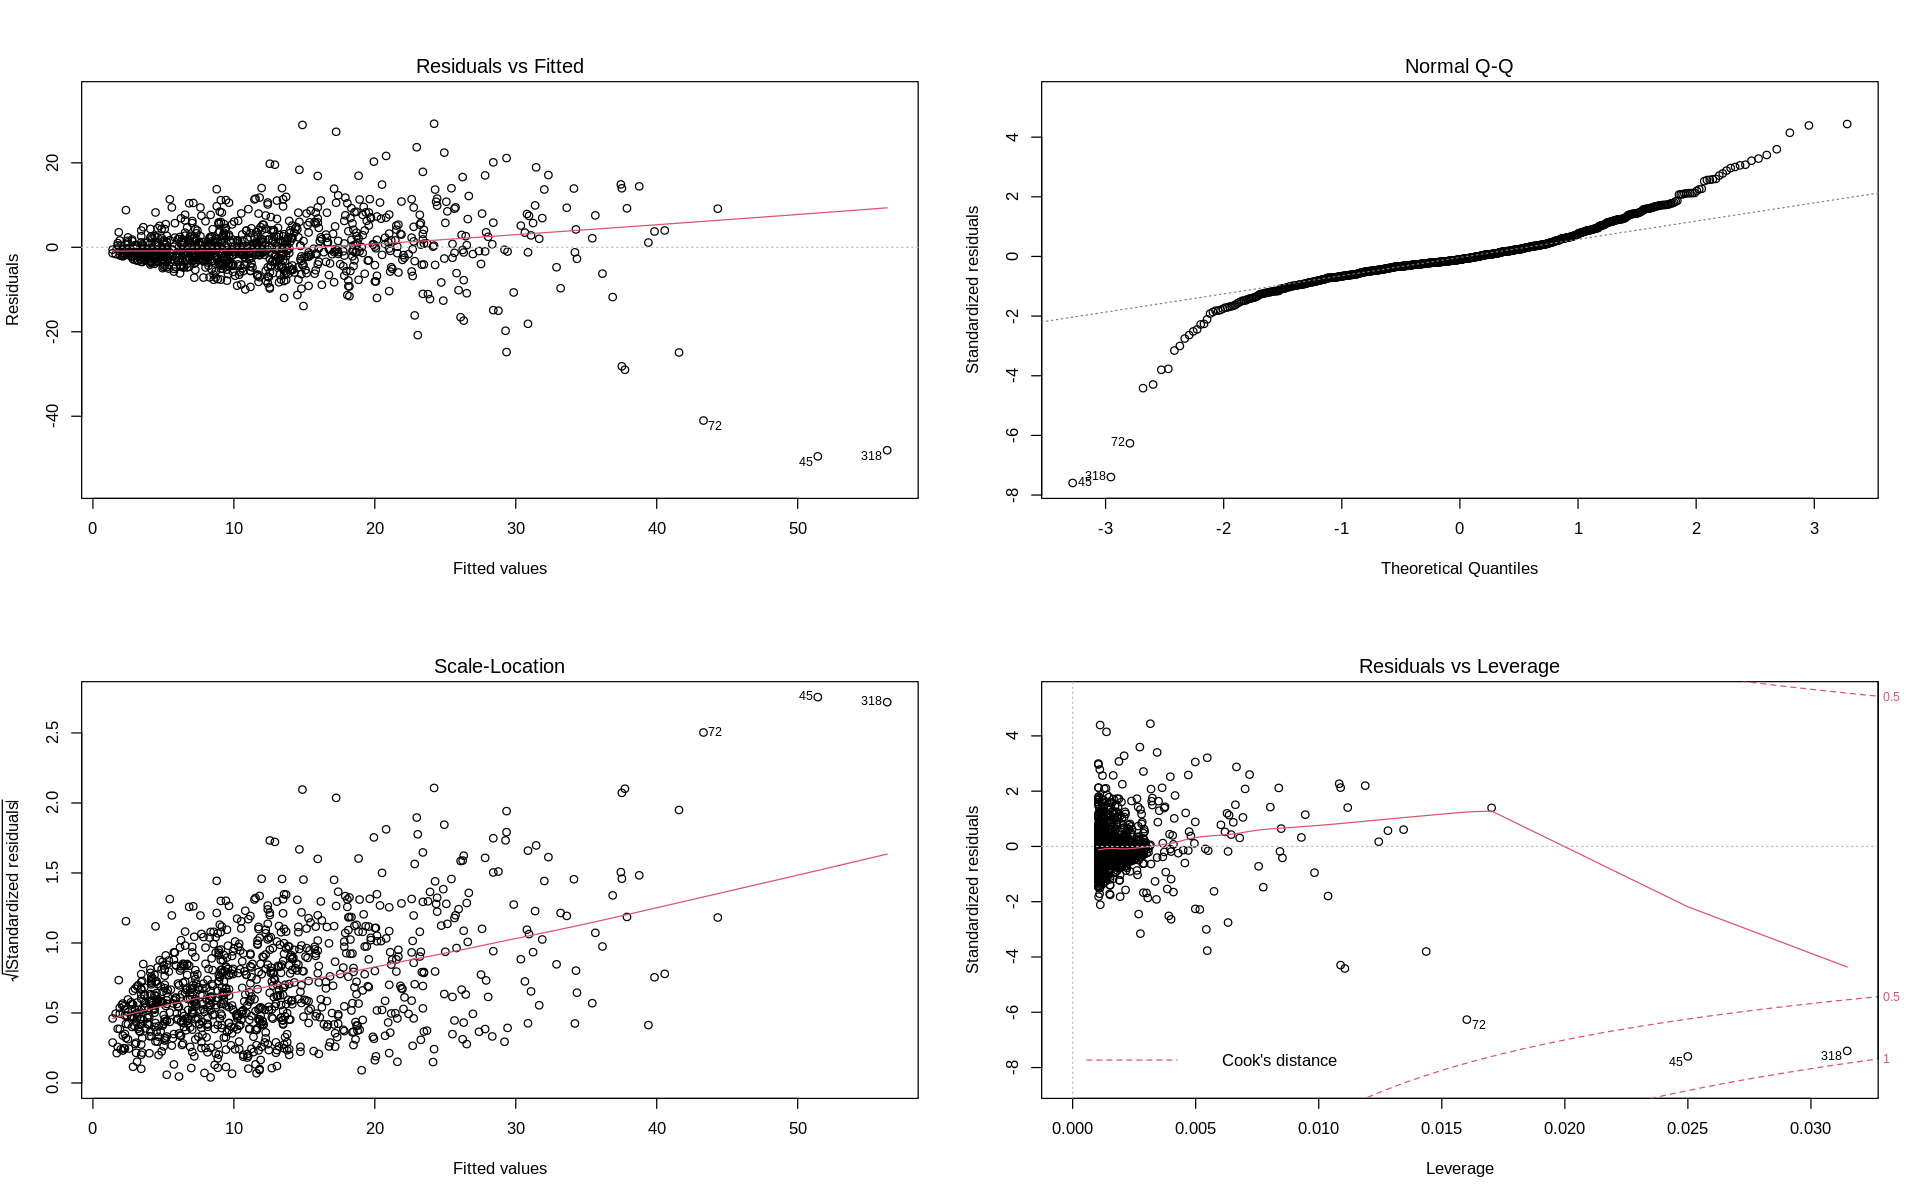

In [97]:
par(mfrow = c(2, 2))
plot(fit1)

Our R-squared value is 0.6003 which I believe is a good starting point, but we will hopefully be able to get closer to 1. When looking at the Residuals vs Fitted plot we see that our fitted line through the residuals does depart from the zero line, but not by too much. Our Normal Q-Q plot shows departure from the our straight line, especially in the tails, which tells us the sample data is not normally distributed. In the Scale-Location plot, our values fan out slightly from the line which indicates a change in the residual variance. In the Residuals vs Leverage plot, we have two values that are past a Cook's distance of 0.5 which indicates they are both influential points. Removing them from our data set would have an impact on our coefficients.

Now, let us add in percent minority to our first model. This is the relationship we are most interested in examining. Ideally, adding in pctMinority to our 

In [98]:
fit2 <- lm(pctSNAP ~ PovertyRate + pctMinority,data=train_data)
summary(fit2)


Call:
lm(formula = pctSNAP ~ PovertyRate + pctMinority, data = train_data)

Residuals:
    Min      1Q  Median      3Q     Max 
-41.102  -3.054  -0.267   2.839  25.087 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 1.075399   0.331818   3.241  0.00123 ** 
PovertyRate 0.588937   0.019557  30.113  < 2e-16 ***
pctMinority 0.124346   0.008469  14.683  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 5.966 on 956 degrees of freedom
Multiple R-squared:  0.6738,	Adjusted R-squared:  0.6732 
F-statistic: 987.5 on 2 and 956 DF,  p-value: < 2.2e-16


It looks like adding in percent Minority does increase our R-squared value to 0.6738 from our previous 0.6017. So we are closer to 1 and showing that PovertyRate and pctMinority can predict pctSNAP with some accuracy.

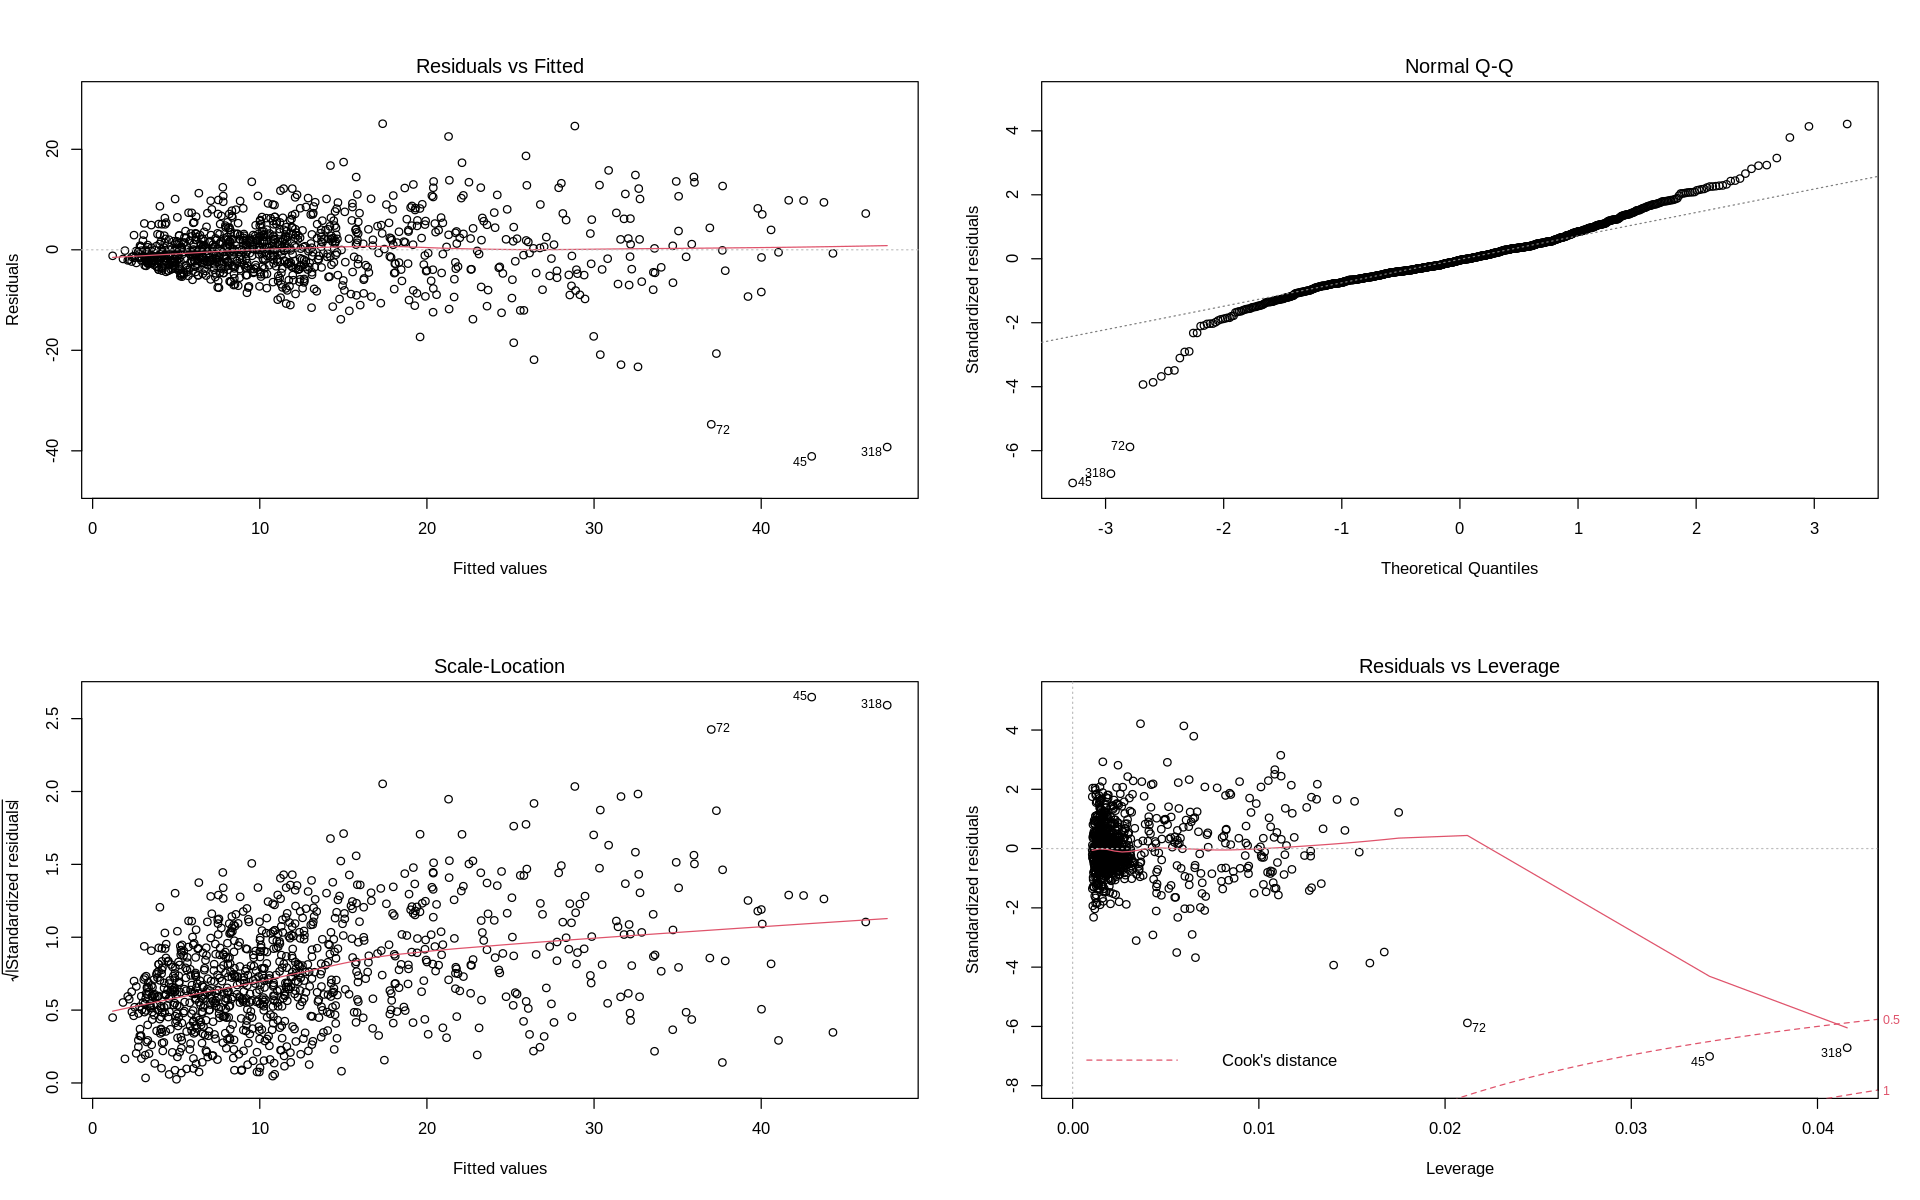

In [99]:
par(mfrow = c(2, 2))
plot(fit2)

The Residuals vs Fitted plot now appears to have a line that gets closer to 0 and our points are scattered around it with some clustering to the left. This tells us that our model is closer to being a good fit for our data. Our Normal Q-Q plot has less departure than the previous model, but still does not fall all on the straight line. Our Scale-Location plot looks very similar to that of the previous model so we have a change in residual variance. In our Residuals vs Leverage plot, our two outliers are still past Cook's distance, so they are influential points to our model.

Now, what will happen if we also account for geographic access to food and being low-income? We will add lalowihalfshare to our model. As a reminder, lalowihalfshare is the share of the tract that lives more than 1/2 mile from a supermarket and are also identified as low-income. Based on the correlation we saw previously between pctSNAP and lalowihalfshare, I think this could have a positive impact on our R-squared value.

In [100]:
fit3 <- lm(pctSNAP ~ PovertyRate + pctMinority + lalowihalfshare,data=train_data)
summary(fit3)


Call:
lm(formula = pctSNAP ~ PovertyRate + pctMinority + lalowihalfshare, 
    data = train_data)

Residuals:
    Min      1Q  Median      3Q     Max 
-38.131  -2.781  -0.351   2.554  27.752 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)    
(Intercept)     -0.162283   0.391104  -0.415    0.678    
PovertyRate      0.513901   0.023254  22.100  < 2e-16 ***
pctMinority      0.129941   0.008387  15.492  < 2e-16 ***
lalowihalfshare  0.086191   0.015005   5.744 1.24e-08 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 5.869 on 955 degrees of freedom
Multiple R-squared:  0.6847,	Adjusted R-squared:  0.6837 
F-statistic: 691.4 on 3 and 955 DF,  p-value: < 2.2e-16


As predicted, lalowihalfshare increases our R-squared value slightly. It went from 0.6738 in fit2 to 0.6847 in fit3.

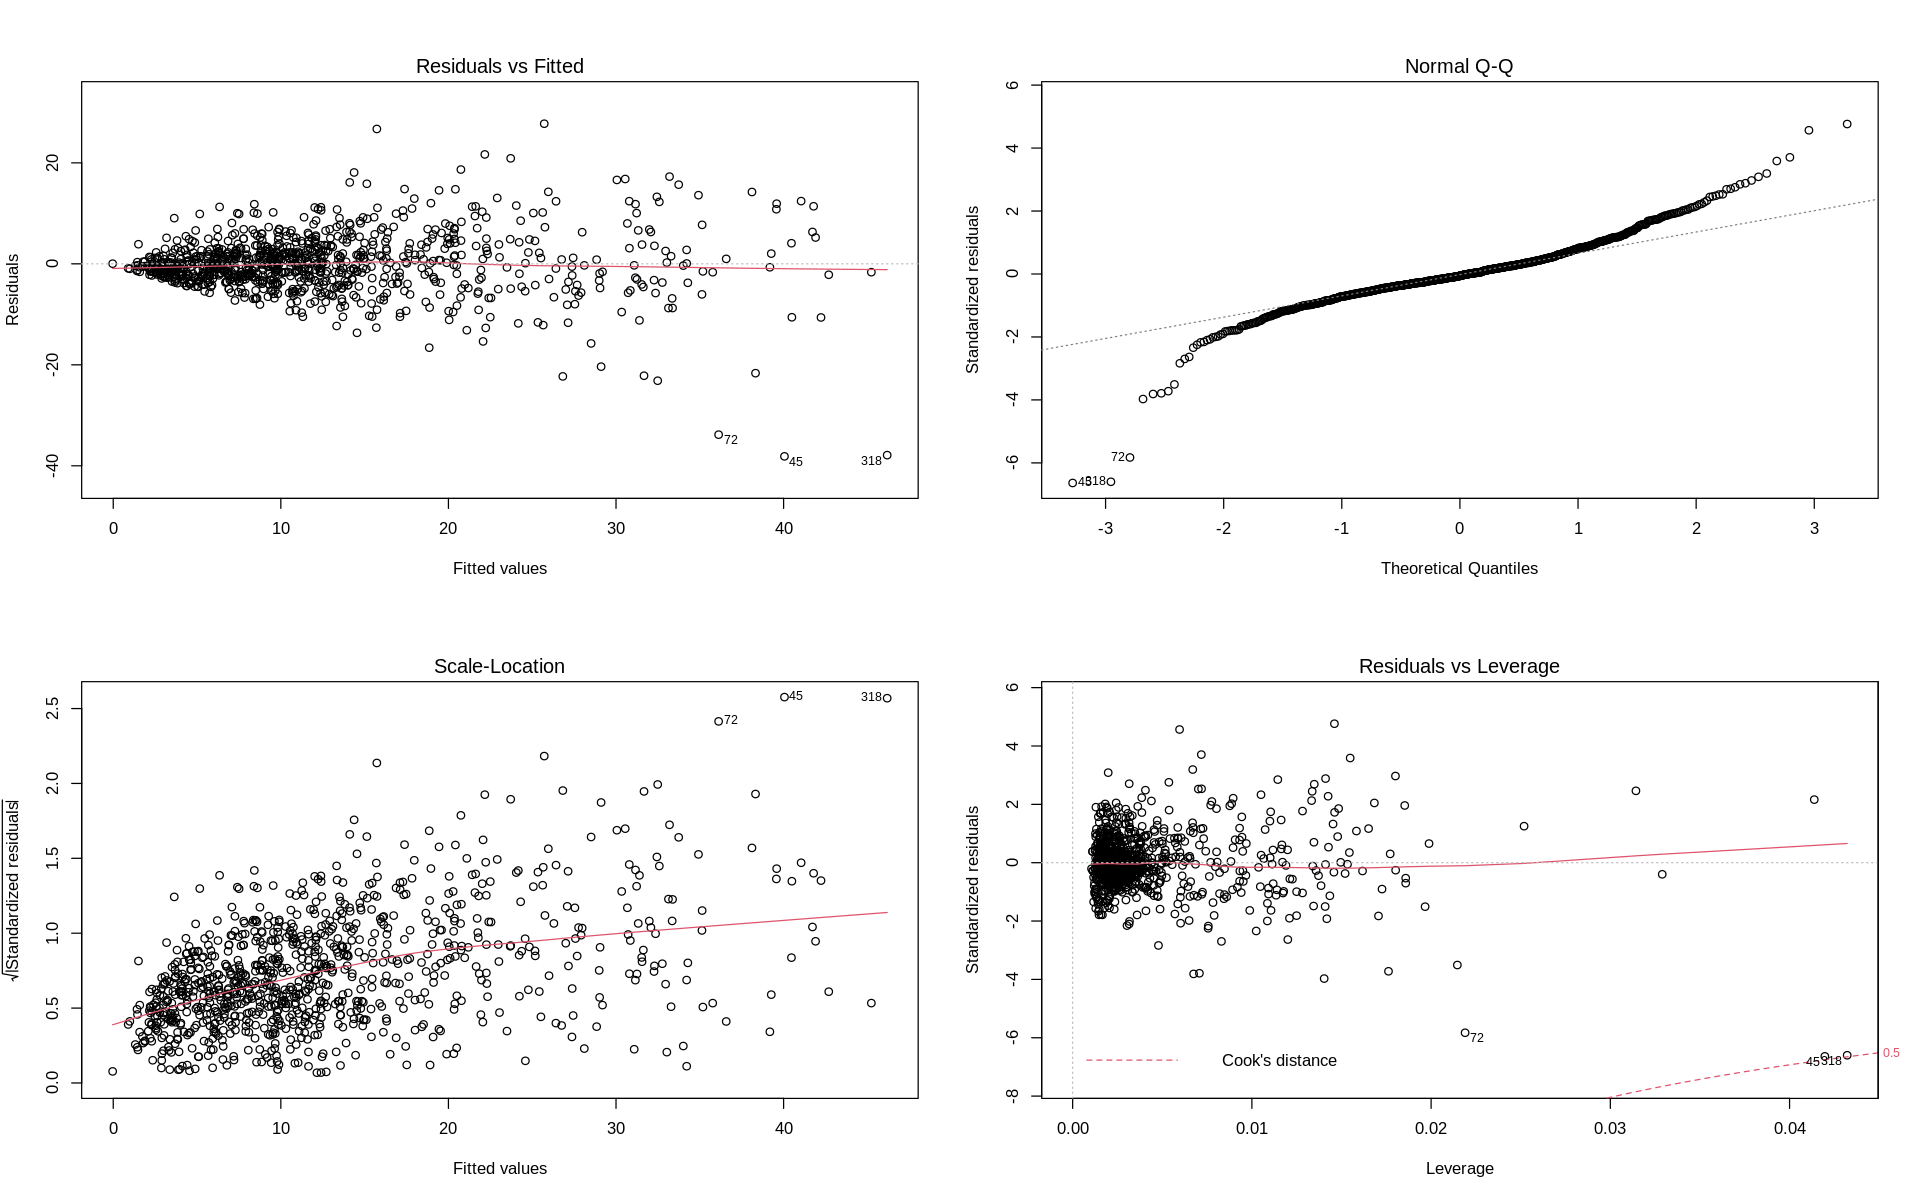

In [101]:
par(mfrow = c(2, 2))
plot(fit3)

Our Residuals vs Fitted plot line has stayed close to zero with points scattered around it and clustered to the left of the plot. The Normal Q-Q plot still shows some departure from the line, but for the most part our data is normally distributed. Our Scale-Location plot does not appear to have changed from fit2. Our Residuals vs Leverage plot has changed from fit2. Our two previous influential points have moved to be just barely outside of Cook's distance. They are close enough to Cook's distance that I think they are still influential on our model.

Now, is there a meaningful interaction between poverty rate and low-income and low-access? We will look at the interaction of Poverty Rate and lalowihalfshare and then add in pctMinority. We are looking at the interaction since PovertyRate also accounts for someone being low income, so there should be some interaction between the two.

In [102]:
fit4 <- lm(pctSNAP ~ PovertyRate * lalowihalfshare + pctMinority,data=train_data)
summary(fit4)


Call:
lm(formula = pctSNAP ~ PovertyRate * lalowihalfshare + pctMinority, 
    data = train_data)

Residuals:
    Min      1Q  Median      3Q     Max 
-34.686  -2.888   0.007   2.621  25.609 

Coefficients:
                              Estimate Std. Error t value Pr(>|t|)    
(Intercept)                 -3.4185858  0.5389304  -6.343 3.47e-10 ***
PovertyRate                  0.7093294  0.0321968  22.031  < 2e-16 ***
lalowihalfshare              0.2284796  0.0221869  10.298  < 2e-16 ***
pctMinority                  0.1338301  0.0081065  16.509  < 2e-16 ***
PovertyRate:lalowihalfshare -0.0071030  0.0008392  -8.464  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 5.663 on 954 degrees of freedom
Multiple R-squared:  0.7068,	Adjusted R-squared:  0.7055 
F-statistic: 574.8 on 4 and 954 DF,  p-value: < 2.2e-16


When we account for amount of housing units in the census tract that are low income and more than 1/2 a mile from the supermarket (lalowihalfshare), we see an increase in our R-squared value to 0.7068 from 0.6847 in fit3. We can now account for 70.68% of the variance in the data with our model.

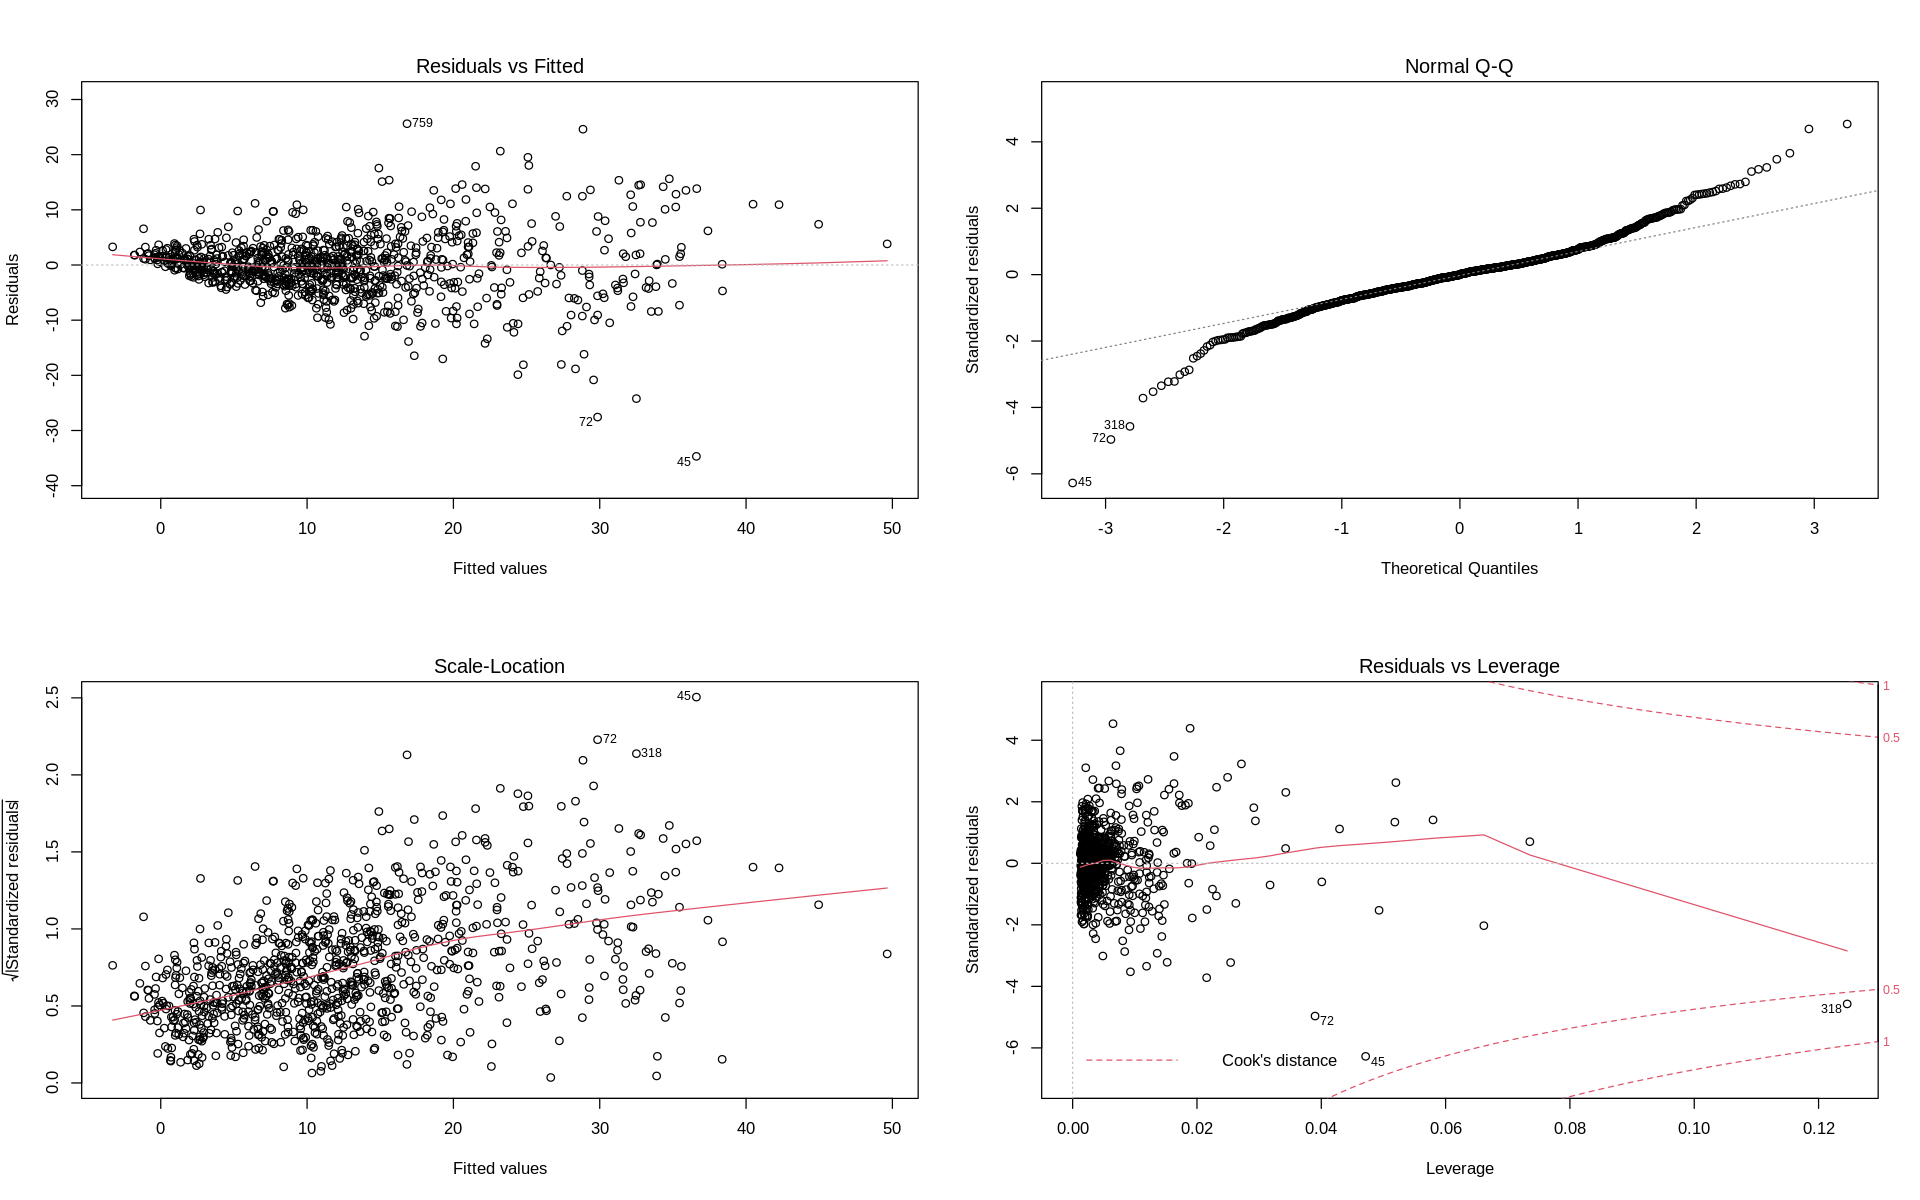

In [103]:
par(mfrow = c(2, 2))
plot(fit4)

Our Residuals vs Fitted, Normal Q-Q, and Scale-Location plots do not have any major changes from fit3. Our Residuals vs Leverage plot now only has one outlier past Cook's distance that could be influential to our model. 

Our next model will also take lapophalfshare into consideration. lapophalfshare is similar to lalowihalfshare and has a low correlation to pctSNAP, so it will most likely not change much in our model.

In [104]:
fit5 <- lm(pctSNAP ~ PovertyRate * lalowihalfshare + pctMinority + lapophalfshare,data=train_data)
summary(fit5)


Call:
lm(formula = pctSNAP ~ PovertyRate * lalowihalfshare + pctMinority + 
    lapophalfshare, data = train_data)

Residuals:
    Min      1Q  Median      3Q     Max 
-33.352  -2.894   0.050   2.710  24.370 

Coefficients:
                              Estimate Std. Error t value Pr(>|t|)    
(Intercept)                  0.8857348  1.0627620   0.833    0.405    
PovertyRate                  0.5966861  0.0399158  14.949  < 2e-16 ***
lalowihalfshare              0.2943658  0.0260718  11.291  < 2e-16 ***
pctMinority                  0.1271479  0.0081450  15.610  < 2e-16 ***
lapophalfshare              -0.0584836  0.0124917  -4.682 3.26e-06 ***
PovertyRate:lalowihalfshare -0.0062976  0.0008478  -7.428 2.44e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 5.602 on 953 degrees of freedom
Multiple R-squared:  0.7133,	Adjusted R-squared:  0.7118 
F-statistic: 474.3 on 5 and 953 DF,  p-value: < 2.2e-16


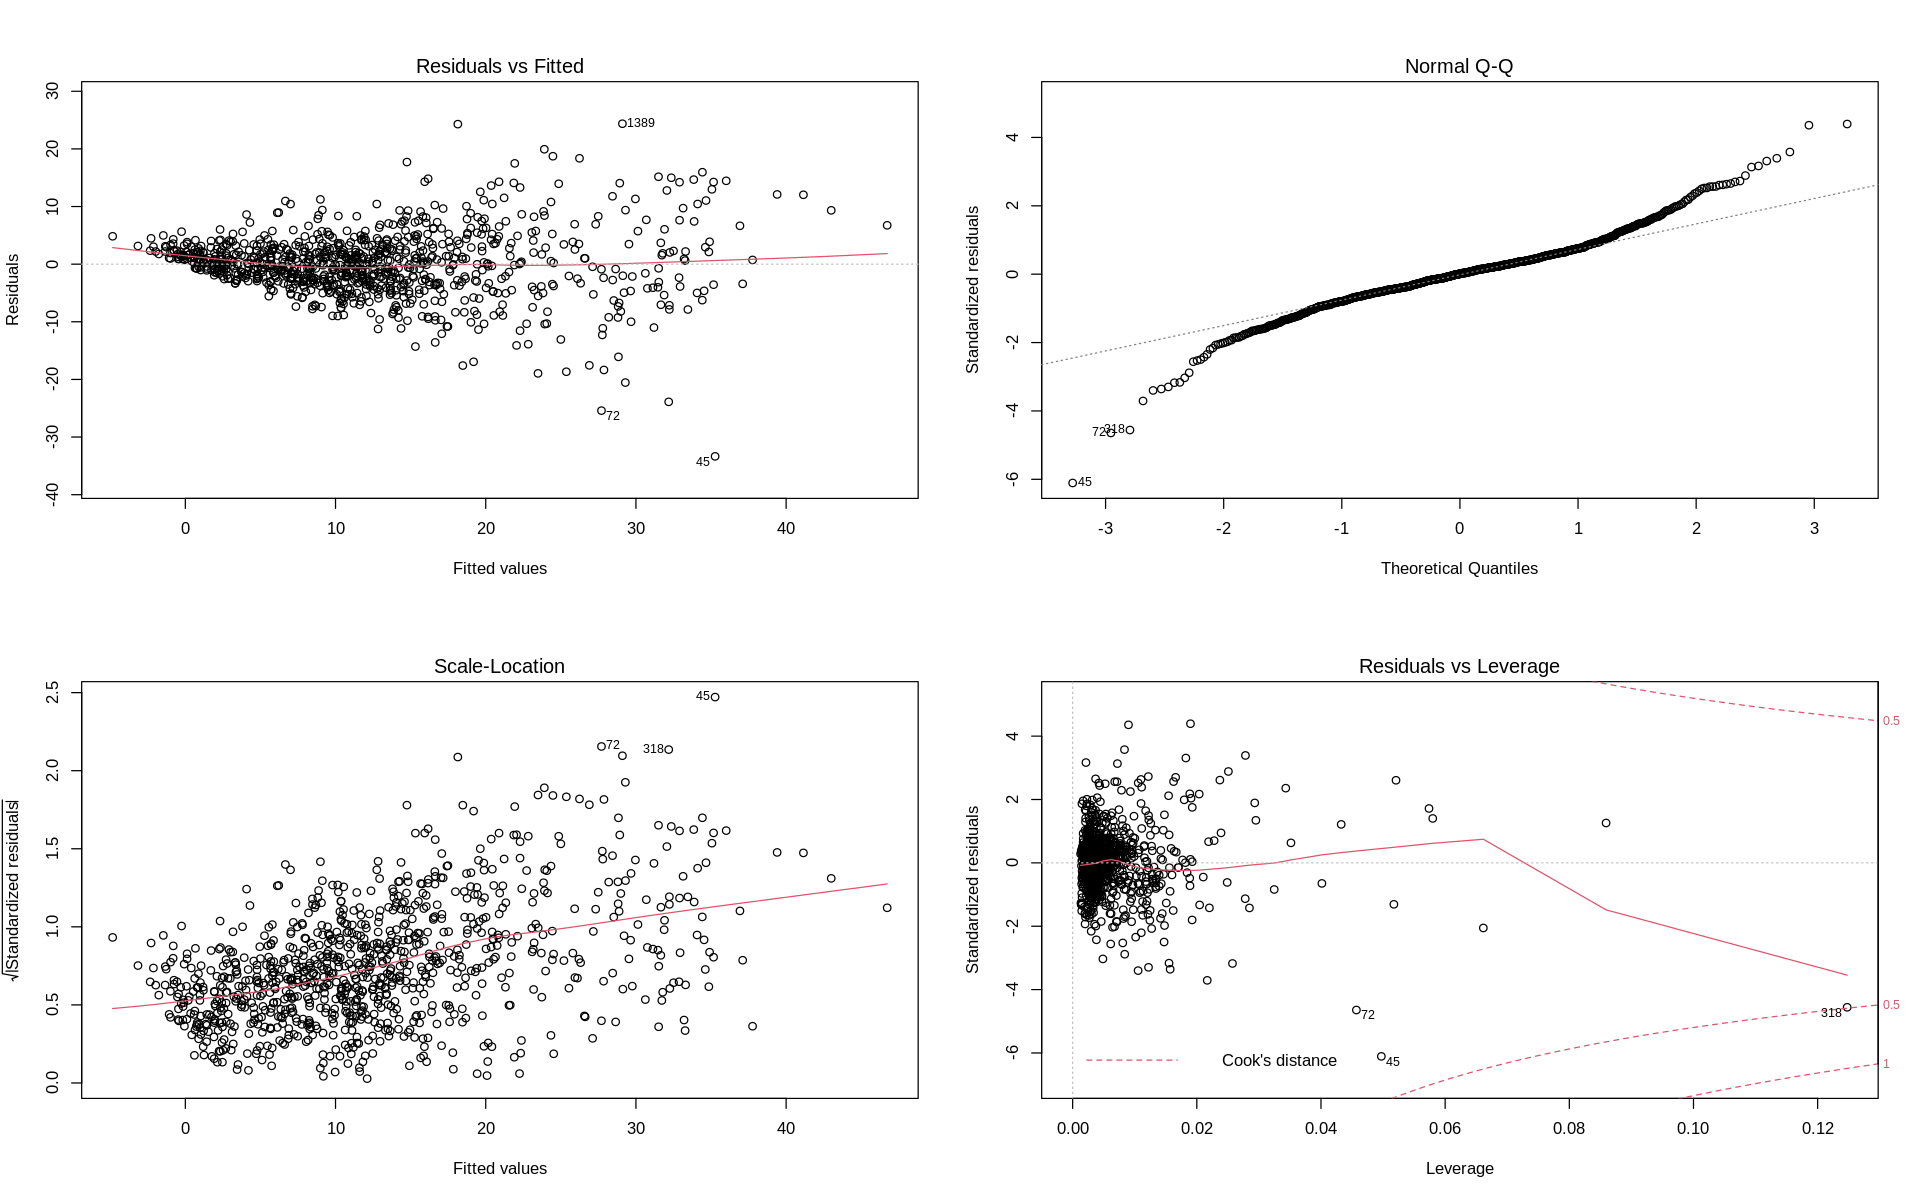

In [105]:
par(mfrow = c(2, 2))
plot(fit5)

We see an increase in our R-squared for fit5 to 0.7133. This is a 0.0065 increase from our R-squared value in fit4, so as predicted, lapophalfshare does not meaningfully change our model. We do see a change in our Residuals vs Leverage plot with just one outlier laying possibly past Cook's distance and being influential to our data. Even though it does not meaningfully change our model, we will still continue with fit5 as our final model since it has the highest R-squared value so far.

In [106]:
summary(fit5)$coefficients

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),0.885734766,1.0627620453,0.8334272,4.048127e-01
PovertyRate,0.596686092,0.0399157729,14.9486293,1.508445e-45
lalowihalfshare,0.294365809,0.0260718381,11.2905660,7.816775e-28
pctMinority,0.127147913,0.0081450447,15.6104624,4.327110e-49
lapophalfshare,-0.058483579,0.0124917066,-4.6817925,3.255828e-06
PovertyRate:lalowihalfshare,-0.006297625,0.0008478069,-7.4281365,2.443912e-13


We can examine our coefficients from fit 5 to assess our model. t value is telling us how many standard deviations our estimate is away from 0. The further it is from 0, the more confidence we can have rejecting our null hypothesis and declare a relationship between pctSNAP and our variables exists. Our t values are far enough from 0, especially relative to our standard error, that I feel confident in rejecting our null hypothesis from this model.

We can now test the accuracy of our model, fit5. To do this we will find predicted values using our test_data and compare them to our true values to find the standard error of estimate. We can then do the same for our train_data and compare the two values.

In [107]:
pred_test = predict(fit5, newdata=test_data)

train_values = as.vector(fitted(fit5))

true_valuesTs = test_data$pctSNAP

true_valuesTr = train_data$pctSNAP

diff_values = pred_test - true_valuesTs
diff_values2 = train_values - true_valuesTr

sqr_diff = diff_values * diff_values
sqr_diff2 = diff_values2 * diff_values2

numerator = sum(sqr_diff)
numerator2 = sum(sqr_diff2)

quot = numerator / (nrow(food_access)-2)
quot2 = numerator2 / (nrow(food_access)-2)

paste("standard error of the estimate for the testing data", sqrt(quot))
paste("standard error of the estimate for the training data", sqrt(quot2)) 

[1] "standard error of the estimate for the testing data 2.95627321375832"

[1] "standard error of the estimate for the training data 4.67395017902902"

We see that our standard error of the estimate is actually lower for our testing data than it is for our training data. This could be for a variety of reasons including overfitting the data or having a simple model. Both standard estimates of error are relatively low, so we can conclude that fit5 does a good job at modeling our data and predicting pctSNAP.

Below we will look at the 10 points with the most difference between their actual value and their predicted value. We will use the absolute value of the difference to account for a point being overpredicted in either direction.

In [108]:
values <- data.frame(actual = test_data$pctSNAP, predicted = pred_test)
values$difference <- abs(values$actual - values$predicted)
values %>% arrange(desc(difference)) %>% head(10)
values %>% arrange(desc(difference)) %>% tail(10)

,actual,predicted,difference
,<dbl>,<dbl>,<dbl>
1092,4.50,28.538197,24.03820
1212,47.22,24.993366,22.22663
811,48.28,27.272552,21.00745
440,53.00,33.120025,19.87998
481,47.61,28.597076,19.01292
757,40.45,22.606723,17.84328
778,37.64,21.883470,15.75653
645,22.03,7.624479,14.40552
833,12.42,25.951374,13.53137


,actual,predicted,difference
,<dbl>,<dbl>,<dbl>
1117,0.40,0.343318,0.05668197
689,13.60,13.654842,0.05484231
901,9.33,9.275954,0.05404553
1282,13.81,13.861817,0.05181712
361,8.64,8.679163,0.03916295
864,3.83,3.862433,0.03243286
1225,15.26,15.233189,0.02681065
146,8.67,8.644392,0.02560796
95,4.46,4.439043,0.02095704


We can see above that the biggest difference between the actual value and it's predicted value is 24.038. This is a pretty big difference so obviously our model is not perfect, but if we look at the tail of the above table, we see many values that our model got very close to with it's predicted value.

## Rinse and repeat 

Evaluation measures can lead to insights that you can use to redo some of the steps to improve your analysis. Try to interpret the confusion matrices, for example: do FP or FN observations have some things in common? How can you rectify the wrong predictions in training the model? Are there any influential points or outliers that affect the models, etc. 


I went through a few iterations of the above process including originally having way too many variables and losing the point of my exploration into the data. I knew I wanted to look at the relationship of percent on SNAP, percentage minority, and poverty rate and it was hard to decide what other variables could be beneficial to keep. I did end up keeping MedianFamilyIncome, lapophalfshare, lalowihalfshare, and county/census identifier variables. As I completed my analysis, I came to the conclusion that pctSNAP can be fairly accurately modeled and predicted using PovertyRate, pctMinority, lalowihalfshare, and lapophalfshare. I did think that low-income low-access would have a higher effect on pctSNAP than was shown in the models. I thought that being low-income and more than 1/2 from a supermarket would be a good indicator someone may be using SNAP benefits.
I think that we could create an even more accurate model using MedianFamilyIncome, but since family income is used to determine SNAP benefits, it seemed it would make the model fitting too easy. 
If I were to continue working with this data set I would shift my focus to food deserts. I considered it as my original hypothesis/plan, but it seemed a little advanced for my skills at the moment.

The percent of people in a tract on SNAP does have a meaningful relationship with Poverty Rate and percent Minority. Using the latter variables as well as accounting for food access, a model was fit. Additionally, it can be visually shown that PovertyRate & pctMinority correlate with pctSNAP. With benefits such as SNAP in the news, it is important to know which communities will be most impacted. The plots in #3 show specific communities that are high minority with a high poverty rate and high percentage of housing units on SNAP. These are likely marginalized communities that will be impacted by changes to SNAP. Knowing where these communities are can lead to action steps like increased donations to local food pantries. 